Connected to Python 3.14.2

In [ ]:
hogar = pd.read_csv("data/raw/hogar_vivienda.csv", sep=";")
hogar.shape

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd
hogar = pd.read_csv("data/raw/hogar_vivienda.csv", sep=";")
hogar.shape

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/hogar_vivienda.csv'

Restarted Python 3.14.2

In [ ]:
import pandas as pd
hogar = pd.read_csv("data/raw/hogar_vivienda.csv", sep=";")
hogar.shape

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/hogar_vivienda.csv'

Restarted Python 3.14.2

In [ ]:
import pandas as pd
hogar = pd.read_csv("data/raw/hogar_vivienda.csv", sep=";")
hogar.shape

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/hogar_vivienda.csv'

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
from pathlib import Path

# Busca hacia arriba la carpeta que contiene data/raw (la raíz del proyecto)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd
hogar = pd.read_csv(RAW / "hogar_vivienda.csv", sep=";")
hogar.shape

(24159, 49)

In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-6-1797a0040ab7>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

NameError: name 'np' is not defined

In [ ]:
import pandas as pd 
per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

NameError: name 'np' is not defined

In [ ]:
import pandas as np
per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

AttributeError: module 'pandas' has no attribute 'nan'

In [ ]:
# Paso 5: resumir las personas de cada hogar
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]
X[cols_p5222] = X[cols_p5222].fillna(0)

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1               179
prop_afiliados_salud      5
P6008                     0
CLASE                     0
P4010                     0
P4020                     0
P4030S1                   0
P4005                     0
hogar_id                  0
P4030S3                   0
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

KeyError: "['razon_dependencia'] not found in axis"

Restarted Python 3.14.2

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
from pathlib import Path

# Busca hacia arriba la carpeta que contiene data/raw (la raíz del proyecto)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-4-0debfaf3e623>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1    179
P5222S7       28
P5222S2       28
P5222S1       28
P5222S5       28
P5222S6       28
P5222S4       28
P5222S3       28
P5222S11      28
P5222S9       28
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
from pathlib import Path

# Busca hacia arriba la carpeta que contiene data/raw (la raíz del proyecto)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-15-0debfaf3e623>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1    179
P5222S7       28
P5222S2       28
P5222S1       28
P5222S5       28
P5222S6       28
P5222S4       28
P5222S3       28
P5222S11      28
P5222S9       28
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
from pathlib import Path

# Busca hacia arriba la carpeta que contiene data/raw (la raíz del proyecto)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-26-0debfaf3e623>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1    179
P5222S7       28
P5222S2       28
P5222S1       28
P5222S5       28
P5222S6       28
P5222S4       28
P5222S3       28
P5222S11      28
P5222S9       28
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
# nombres de las variables 
NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",

_IncompleteInputError: incomplete input (<ipython-input-34-1c8ec45d4f82>, line 25)

In [ ]:
# nombres de las variables 
NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
}

In [ ]:
# Nombres de las variables 
NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

X = X.rename(columns=NOMBRES)
list(X.columns)

['hogar_id',
 'clase',
 'n_personas',
 'tipo_vivienda',
 'material_paredes',
 'material_pisos',
 'tiene_energia',
 'tiene_gas_natural',
 'tiene_alcantarillado',
 'tiene_recoleccion_basuras',
 'tiene_acueducto',
 'estrato',
 'n_cuartos',
 'n_dormitorios',
 'tipo_sanitario',
 'lugar_cocina',
 'combustible_cocina',
 'tenencia_vivienda',
 'fin_cuenta_corriente',
 'fin_cuenta_ahorros',
 'fin_cdt',
 'fin_prestamo_vivienda',
 'fin_prestamo_vehiculo',
 'fin_prestamo_libre_inversion',
 'fin_tarjeta_credito',
 'fin_otro',
 'fin_ninguno',
 'fin_billetera_movil',
 'edad_jefe',
 'sexo_jefe',
 'educ_jefe',
 'n_menores15',
 'n_mayores65',
 'n_edad_trabajo',
 'prop_afiliados_salud',
 'prop_subsidiado',
 'n_ocupados',
 'n_cotizantes',
 'posicion_ocup_jefe',
 'prop_dependientes']

Restarted Python 3.14.2

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
from pathlib import Path

# Busca hacia arriba la carpeta que contiene data/raw (la raíz del proyecto)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-4-0debfaf3e623>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1    179
P5222S7       28
P5222S2       28
P5222S1       28
P5222S5       28
P5222S6       28
P5222S4       28
P5222S3       28
P5222S11      28
P5222S9       28
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
# Nombres de las variables 
NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

X = X.rename(columns=NOMBRES)
# Servicios: el DANE usa 1 = sí, 2 = no. Se pasa a 1 = sí, 0 = no
COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]
X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
list(X.columns)

['hogar_id',
 'clase',
 'n_personas',
 'tipo_vivienda',
 'material_paredes',
 'material_pisos',
 'tiene_energia',
 'tiene_gas_natural',
 'tiene_alcantarillado',
 'tiene_recoleccion_basuras',
 'tiene_acueducto',
 'estrato',
 'n_cuartos',
 'n_dormitorios',
 'tipo_sanitario',
 'lugar_cocina',
 'combustible_cocina',
 'tenencia_vivienda',
 'fin_cuenta_corriente',
 'fin_cuenta_ahorros',
 'fin_cdt',
 'fin_prestamo_vivienda',
 'fin_prestamo_vehiculo',
 'fin_prestamo_libre_inversion',
 'fin_tarjeta_credito',
 'fin_otro',
 'fin_ninguno',
 'fin_billetera_movil',
 'edad_jefe',
 'sexo_jefe',
 'educ_jefe',
 'n_menores15',
 'n_mayores65',
 'n_edad_trabajo',
 'prop_afiliados_salud',
 'prop_subsidiado',
 'n_ocupados',
 'n_cotizantes',
 'posicion_ocup_jefe',
 'prop_dependientes']

In [ ]:
#verificar que no quede ninguna variable sin nombrar
[c for c in X.columns if c.startswith("P")]

[]

In [ ]:
# Paso 10: reducir la muestra y registrar el embudo
embudo = {"Hogares GEIH": len(X)}

# Filtro 1: solo cabeceras (zona urbana)
X_cab = X[X["clase"] == 1].drop(columns=["clase"])
embudo["Cabeceras (clase = 1)"] = len(X_cab)

# Filtro 2: casos completos (sin ningún vacío)
completo = X_cab.notna().all(axis=1)
X_final = X_cab[completo].copy()
excluidos = X_cab[~completo].copy()       # se guardan para compararlos en reduccion_muestra.md
embudo["Casos completos"] = len(X_final)

for paso, n in embudo.items():
    print(f"{paso}: {n:,}")
print("Excluidos por vacíos:", len(excluidos))

# ¿Qué variables causaron las exclusiones?
excluidos.isna().sum()[lambda s: s > 0]

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Casos completos: 20,991
Excluidos por vacíos: 46


estrato                         16
fin_cuenta_corriente            28
fin_cuenta_ahorros              28
fin_cdt                         28
fin_prestamo_vivienda           28
fin_prestamo_vehiculo           28
fin_prestamo_libre_inversion    28
fin_tarjeta_credito             28
fin_otro                        28
fin_ninguno                     28
fin_billetera_movil             28
prop_afiliados_salud             2
dtype: int64

In [ ]:
EN_TARGET = {
    "INGLABO",               # ingreso laboral
    "P6500",                 # salario
    "P6750",                 # ganancia del trabajo independiente
    "P7500S2", "P7500S2A1",  # recibió pensión / monto
    "P5130",                 # arriendo imputado (confirmar con target.py)
    "ypc", "ses",            # del contrato: ingreso per cápita y el target
}
MONETARIAS = {
    "P5100",  # cuota mensual de la vivienda
    "P5110",  # cuota de amortización
    "P5140",  # arriendo pagado
}
IDENTIFICADORES = {"hogar_id", "DIRECTORIO", "SECUENCIA_P", "ORDEN", "HOGAR", "FEX_C18", "PERIODO", "MES"}


PROHIBIDAS = EN_TARGET | MONETARIAS | IDENTIFICADORES

def assert_no_leakage(columns):
    malas = {c for c in columns if set(c.split("__")) & PROHIBIDAS}
    assert not malas, f"Variables prohibidas en X: {malas}"

#PRUEBAS 
if __name__ == "__main__":
    # Prueba 1: columnas permitidas, no debe fallar
    assert_no_leakage(["P5000", "P4010", "edad_jefe"])
    print("Prueba 1 OK: sin fuga")

    # Prueba 2: una columna prohibida con prefijo del Pipeline, debe fallar
    try:
        assert_no_leakage(["P5000", "num__P5140"])
        print("Prueba 2 FALLÓ: el guardia no detectó la fuga")
    except AssertionError as e:
        print("Prueba 2 OK: detectó la fuga ->", e)

Prueba 1 OK: sin fuga
Prueba 2 OK: detectó la fuga -> Variables prohibidas en X: {'num__P5140'}


In [ ]:
# Paso 11: revisar fuga y guardar

# 1) Guardia de fuga
assert_no_leakage(list(NOMBRES.keys()))                      # variables GEIH de origen
assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales (sin la llave)
print("Sin fuga ✔")

# 2) Archivo del contrato
PROCESSED.mkdir(parents=True, exist_ok=True)
X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
print("Guardado:", PROCESSED / "X_hogar.parquet", X_final.shape)

# 3) Material para docs/reduccion_muestra.md
INTERIM = RAIZ / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)
excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])
print("Guardados excluidos y embudo en data/interim")

Sin fuga ✔


NameError: name 'PROCESSED' is not defined

Restarted Python 3.14.2

In [ ]:
import os
print("Estoy en:", os.getcwd())
print("¿Existe el archivo?", os.path.exists("data/raw/hogar_vivienda.csv"))

Estoy en: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\features
¿Existe el archivo? False


In [ ]:
# Paso 0: ubicar la raíz del proyecto (funciona en cualquier computador)
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))   # para poder importar leakage.py

from ses.features.leakage import assert_no_leakage

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status


In [ ]:
import pandas as pd

def leer(nombre):
    """Lee un CSV de data/raw. Prueba primero utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)

hogar = leer("hogar_vivienda.csv")
personas = leer("personas_salud_educacion.csv")   # <- revisa el nombre exacto
ocupados = leer("ocupados.csv")

print("hogar:", hogar.shape)
print("personas:", personas.shape)
print("ocupados:", ocupados.shape)

hogar: (24159, 49)
personas: (66559, 55)
ocupados: (29611, 202)


In [ ]:
def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    tabla["hogar_id"] = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return tabla

hogar = crear_llave(hogar)
personas = crear_llave(personas)
ocupados = crear_llave(ocupados)

print("¿hogar_id único en hogar?", hogar["hogar_id"].is_unique)
print(hogar["hogar_id"].head())

¿hogar_id único en hogar? True
0    8435963_1_1
1    8435964_1_1
2    8435965_1_1
3    8435966_1_1
4    8435967_1_1
Name: hogar_id, dtype: str


<ipython-input-4-0debfaf3e623>:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tabla["hogar_id"] = (


In [ ]:
COLS_VIVIENDA = [
    "P4005",                                              # tipo de vivienda
    "P4010", "P4020",                                     # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                          # estrato
    "P5000", "P5010",                                     # cuartos y dormitorios
    "P5020",                                              # sanitario
    "P5070", "P5080",                                     # lugar y combustible para cocinar
    "P5090",                                              # tenencia de la vivienda
] + [f"P5222S{i}" for i in range(1, 12)]                  # bienes del hogar (S1 a S11)

vivienda = hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()
print("vivienda:", vivienda.shape)

vivienda: (24159, 29)


In [ ]:
jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()

print("jefe:", jefe.shape)
print("¿un jefe por hogar?", jefe["hogar_id"].is_unique)

jefe: (24159, 4)
¿un jefe por hogar? True


In [ ]:
import numpy as np

per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()

# 1) Marcar a cada persona con 1/0
per["es_menor15"] = (per["P6040"] < 15).astype(int)
per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})            # 9 (no sabe) queda vacío
per["subsidiado"] = (per["P6100"] == 3).astype(int)               # 3 = régimen subsidiado

# 2) Agrupar por hogar
resumen_personas = per.groupby("hogar_id").agg(
    n_menores15=("es_menor15", "sum"),
    n_mayores65=("es_mayor65", "sum"),
    n_edad_trabajo=("es_edad_trabajo", "sum"),
    prop_afiliados_salud=("afiliado_salud", "mean"),
    prop_subsidiado=("subsidiado", "mean"),
).reset_index()

# 3) Razón de dependencia: personas dependientes por cada persona en edad de trabajar
resumen_personas["razon_dependencia"] = (
    (resumen_personas["n_menores15"] + resumen_personas["n_mayores65"])
    / resumen_personas["n_edad_trabajo"].replace(0, np.nan)
)

print("resumen_personas:", resumen_personas.shape)
resumen_personas.head()

resumen_personas: (24159, 7)


,hogar_id,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia
0,8435963_1_1,1,0,2,1.0,1.0,0.5
1,8435964_1_1,0,1,0,1.0,1.0,NaN
2,8435965_1_1,0,1,0,1.0,1.0,NaN
3,8435966_1_1,0,1,0,1.0,1.0,NaN
4,8435967_1_1,0,0,1,1.0,1.0,0.0


In [ ]:
# Resumir los ocupados de cada hogar
ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)          # 1 = sí cotiza

resumen_ocupados = ocu.groupby("hogar_id").agg(
    n_ocupados=("ORDEN", "count"),
    n_cotizantes=("cotiza_pension", "sum"),
).reset_index()

# Posición ocupacional del jefe: cruzar ocupados con el ORDEN del jefe
orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
pos_jefe = ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
pos_jefe = pos_jefe.rename(columns={"P6430": "posicion_ocup_jefe"})

print("resumen_ocupados:", resumen_ocupados.shape)
print("jefes ocupados:", pos_jefe.shape)

resumen_ocupados: (19594, 3)
jefes ocupados: (15772, 2)


In [ ]:
#unir todas las tablas en una sola fila por hogar
X = (
    vivienda
    .merge(jefe, on="hogar_id", how="left")
    .merge(resumen_personas, on="hogar_id", how="left")
    .merge(resumen_ocupados, on="hogar_id", how="left")
    .merge(pos_jefe, on="hogar_id", how="left")
)

# Hogares sin nadie trabajando: no aparecen en resumen_ocupados, así que quedan vacíos.
# En realidad tienen 0 ocupados y 0 cotizantes.
X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)

# Jefe que no trabaja: no tiene posición ocupacional. Se marca con 0 = "jefe no ocupado".
X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)

print("X:", X.shape)
print("¿un hogar por fila?", X["hogar_id"].is_unique)
X.head()

X: (24159, 41)
¿un hogar por fila? True


,hogar_id,CLASE,P6008,P4005,P4010,P4020,P4030S1,P4030S2,P4030S3,P4030S4,...,P3042,n_menores15,n_mayores65,n_edad_trabajo,prop_afiliados_salud,prop_subsidiado,razon_dependencia,n_ocupados,n_cotizantes,posicion_ocup_jefe
0,8435963_1_1,2,3,1,5,1,2,2,2,2,...,5.0,1,0,2,1.0,1.0,0.5,2.0,0.0,4.0
1,8435964_1_1,2,1,1,5,1,2,2,2,2,...,1.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
2,8435965_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
3,8435966_1_1,2,1,1,5,1,2,2,2,2,...,3.0,0,1,0,1.0,1.0,NaN,1.0,0.0,4.0
4,8435967_1_1,2,1,1,5,1,2,2,2,2,...,5.0,0,0,1,1.0,1.0,0.0,1.0,0.0,4.0


In [ ]:
#vacíos que en realidad tienen significado

# P5222: pregunta de "marque todas". Vacío = no la marcó = 0
cols_p5222 = [f"P5222S{i}" for i in range(1, 12)]

# Antes de rellenar: ¿qué hogares no sabemos qué productos usan?
sin_respuesta = X[cols_p5222].isna().all(axis=1)    # no marcaron ninguna opción
no_sabe = X["P5222S10"] == 1                         # marcaron "No sabe"

X[cols_p5222] = X[cols_p5222].fillna(0)              # vacío = no marcó esa opción = 0
X.loc[sin_respuesta | no_sabe, cols_p5222] = np.nan  # esos hogares quedan vacíos de verdad
X = X.drop(columns=["P5222S10"])                     # "No sabe" ya no es un predictor

# P5080: vacío cuando el hogar no cocina (P5070 = 6). Se marca como 0 = "no cocina"
X.loc[X["P5070"] == 6, "P5080"] = 0

# Razón de dependencia -> proporción de dependientes (nunca divide entre 0)
X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
X = X.drop(columns=["razon_dependencia"])

X.isna().sum().sort_values(ascending=False).head(10)

P4030S1A1    179
P5222S7       28
P5222S2       28
P5222S1       28
P5222S5       28
P5222S6       28
P5222S4       28
P5222S3       28
P5222S11      28
P5222S9       28
dtype: int64

In [ ]:
# - vacío = el hogar no tiene energía (no se preguntó) -> categoría propia: 7 = "sin energía"
# - 9 = no sabe -> vacío de verdad (se elimina en el filtro de casos completos)
X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

X["P4030S1A1"].value_counts(dropna=False).sort_index()

P4030S1A1
0.0     506
1.0    8719
2.0    7848
3.0    4873
4.0    1138
5.0     476
6.0     245
7.0     179
NaN     175
Name: count, dtype: int64

In [ ]:
# Nombres de las variables 
NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

X = X.rename(columns=NOMBRES)
# Servicios: el DANE usa 1 = sí, 2 = no. Se pasa a 1 = sí, 0 = no
COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]
X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
list(X.columns)

['hogar_id',
 'clase',
 'n_personas',
 'tipo_vivienda',
 'material_paredes',
 'material_pisos',
 'tiene_energia',
 'tiene_gas_natural',
 'tiene_alcantarillado',
 'tiene_recoleccion_basuras',
 'tiene_acueducto',
 'estrato',
 'n_cuartos',
 'n_dormitorios',
 'tipo_sanitario',
 'lugar_cocina',
 'combustible_cocina',
 'tenencia_vivienda',
 'fin_cuenta_corriente',
 'fin_cuenta_ahorros',
 'fin_cdt',
 'fin_prestamo_vivienda',
 'fin_prestamo_vehiculo',
 'fin_prestamo_libre_inversion',
 'fin_tarjeta_credito',
 'fin_otro',
 'fin_ninguno',
 'fin_billetera_movil',
 'edad_jefe',
 'sexo_jefe',
 'educ_jefe',
 'n_menores15',
 'n_mayores65',
 'n_edad_trabajo',
 'prop_afiliados_salud',
 'prop_subsidiado',
 'n_ocupados',
 'n_cotizantes',
 'posicion_ocup_jefe',
 'prop_dependientes']

In [ ]:
#verificar que no quede ninguna variable sin nombrar
[c for c in X.columns if c.startswith("P")]

[]

In [ ]:
# Paso 10: reducir la muestra y registrar el embudo
embudo = {"Hogares GEIH": len(X)}

# Filtro 1: solo cabeceras (zona urbana)
X_cab = X[X["clase"] == 1].drop(columns=["clase"])
embudo["Cabeceras (clase = 1)"] = len(X_cab)

# Filtro 2: casos completos (sin ningún vacío)
completo = X_cab.notna().all(axis=1)
X_final = X_cab[completo].copy()
excluidos = X_cab[~completo].copy()       # se guardan para compararlos en reduccion_muestra.md
embudo["Casos completos"] = len(X_final)

for paso, n in embudo.items():
    print(f"{paso}: {n:,}")
print("Excluidos por vacíos:", len(excluidos))

# ¿Qué variables causaron las exclusiones?
excluidos.isna().sum()[lambda s: s > 0]

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Casos completos: 20,991
Excluidos por vacíos: 46


estrato                         16
fin_cuenta_corriente            28
fin_cuenta_ahorros              28
fin_cdt                         28
fin_prestamo_vivienda           28
fin_prestamo_vehiculo           28
fin_prestamo_libre_inversion    28
fin_tarjeta_credito             28
fin_otro                        28
fin_ninguno                     28
fin_billetera_movil             28
prop_afiliados_salud             2
dtype: int64

In [ ]:
# Revisar fuga 

# 1) Guardia de fuga
assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales (sin la llave)
print("Sin fuga ✔")

# 2) Archivo del contrato
PROCESSED.mkdir(parents=True, exist_ok=True)
X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
print("Guardado:", PROCESSED / "X_hogar.parquet", X_final.shape)

# 3) Material para docs/reduccion_muestra.md
INTERIM = RAIZ / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)
excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])
print("Guardados excluidos y embudo en data/interim")# %%

Sin fuga ✔
Guardado: c:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\data\processed\X_hogar.parquet (20991, 39)
Guardados excluidos y embudo en data/interim


Restarted Python 3.14.2

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Rutas (funcionan en cualquier computador)
# ---------------------------------------------------------------------------
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))

from ses.features.leakage import assert_no_leakage  # noqa: E402

ARCHIVO_HOGAR = "hogar_vivienda.csv"
ARCHIVO_PERSONAS = "personas_salud_educacion.csv"   # <- nombre exacto del archivo
ARCHIVO_OCUPADOS = "ocupados.csv"

# ---------------------------------------------------------------------------
# Variables (ver docs/matriz_fuga.md)
# ---------------------------------------------------------------------------
COLS_P5222 = [f"P5222S{i}" for i in range(1, 12)]   # productos financieros (selección múltiple)

COLS_VIVIENDA = [
    "P4005",                                                # tipo de vivienda
    "P4010", "P4020",                                       # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                            # estrato
    "P5000", "P5010",                                       # cuartos y dormitorios
    "P5020",                                                # sanitario
    "P5070", "P5080",                                       # lugar y combustible para cocinar
    "P5090",                                                # tenencia de la vivienda
] + COLS_P5222

NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]


# ---------------------------------------------------------------------------
# Pasos 1-2: lectura y llave
# ---------------------------------------------------------------------------
def leer(nombre):
    """Lee un CSV de data/raw. Prueba utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)


def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    llave = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return pd.concat([tabla, llave.rename("hogar_id")], axis=1)


def cargar_datos():
    """Lee los tres módulos y les agrega la llave hogar_id."""
    hogar = crear_llave(leer(ARCHIVO_HOGAR))
    personas = crear_llave(leer(ARCHIVO_PERSONAS))
    ocupados = crear_llave(leer(ARCHIVO_OCUPADOS))
    assert hogar["hogar_id"].is_unique, "hogar_id repetido en la tabla de hogares"
    return hogar, personas, ocupados


# ---------------------------------------------------------------------------
# Pasos 3-6: variables por bloque
# ---------------------------------------------------------------------------
def variables_vivienda(hogar):
    """Paso 3: vivienda (bloque B), tamaño del hogar (bloque A) y CLASE para filtrar."""
    return hogar[["hogar_id", "CLASE", "P6008"] + COLS_VIVIENDA].copy()


def variables_jefe(personas):
    """Paso 4: edad, sexo y educación del jefe de hogar (P6050 = 1)."""
    jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()
    assert jefe["hogar_id"].is_unique, "hay hogares con más de un jefe"
    return jefe


def resumen_personas(personas):
    """Paso 5: conteos y proporciones de las personas de cada hogar."""
    per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()
    per["es_menor15"] = (per["P6040"] < 15).astype(int)
    per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
    per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
    per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})   # 9 (no sabe) queda vacío
    per["subsidiado"] = (per["P6100"] == 3).astype(int)      # 3 = régimen subsidiado

    return per.groupby("hogar_id").agg(
        n_menores15=("es_menor15", "sum"),
        n_mayores65=("es_mayor65", "sum"),
        n_edad_trabajo=("es_edad_trabajo", "sum"),
        prop_afiliados_salud=("afiliado_salud", "mean"),
        prop_subsidiado=("subsidiado", "mean"),
    ).reset_index()


def resumen_ocupados(ocupados, personas):
    """Paso 6: ocupados y cotizantes del hogar, y posición ocupacional del jefe (bloque C)."""
    ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
    ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)   # 1 = sí cotiza

    resumen = ocu.groupby("hogar_id").agg(
        n_ocupados=("ORDEN", "count"),
        n_cotizantes=("cotiza_pension", "sum"),
    ).reset_index()

    orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
    pos_jefe = (ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
                .rename(columns={"P6430": "posicion_ocup_jefe"}))
    return resumen, pos_jefe


# ---------------------------------------------------------------------------
# Pasos 7-9: unión, limpieza y nombres
# ---------------------------------------------------------------------------
def unir(vivienda, jefe, res_personas, res_ocupados, pos_jefe):
    """Paso 7: una fila por hogar. Vacíos de ocupados = 0 (nadie trabaja)."""
    X = (vivienda
         .merge(jefe, on="hogar_id", how="left")
         .merge(res_personas, on="hogar_id", how="left")
         .merge(res_ocupados, on="hogar_id", how="left")
         .merge(pos_jefe, on="hogar_id", how="left"))
    assert len(X) == len(vivienda), "el merge duplicó hogares"

    X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)
    X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)   # 0 = jefe no ocupado
    return X


def limpiar_codigos(X):
    """Pasos 7b y 8: vacíos con significado y códigos de 'no sabe'."""
    # P5222 (selección múltiple): vacío = no marcó = 0.
    # Sin ninguna opción marcada o con "No sabe" (S10) -> vacío de verdad.
    sin_respuesta = X[COLS_P5222].isna().all(axis=1)
    no_sabe = X["P5222S10"] == 1
    X[COLS_P5222] = X[COLS_P5222].fillna(0)
    X.loc[sin_respuesta | no_sabe, COLS_P5222] = np.nan
    X = X.drop(columns=["P5222S10"])

    # P5080: no se pregunta si el hogar no cocina (P5070 = 6) -> 0 = "no cocina"
    X.loc[X["P5070"] == 6, "P5080"] = 0

    # Estrato: sin energía (no se preguntó) -> 7; 9 = no sabe -> vacío
    X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
    X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

    # Proporción de dependientes (reemplaza la razón de dependencia: nunca divide entre 0)
    X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
    return X


def renombrar(X):
    """Paso 9: nombres en snake_case y servicios como 1 = sí, 0 = no."""
    X = X.rename(columns=NOMBRES)
    X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
    return X


# ---------------------------------------------------------------------------
# Paso 10: reducción de la muestra
# ---------------------------------------------------------------------------
def filtrar_muestra(X):
    """Cabeceras y casos completos. Devuelve X final, excluidos y el embudo."""
    embudo = {"Hogares GEIH": len(X)}

    X_cab = X[X["clase"] == 1].drop(columns=["clase"])
    embudo["Cabeceras (clase = 1)"] = len(X_cab)

    completo = X_cab.notna().all(axis=1)
    X_final = X_cab[completo].copy()
    excluidos = X_cab[~completo].copy()
    embudo["Casos completos"] = len(X_final)
    return X_final, excluidos, embudo


# ---------------------------------------------------------------------------
# Flujo completo
# ---------------------------------------------------------------------------
def construir_X():
    """Corre los pasos 1 a 10 y devuelve X final, excluidos y embudo."""
    hogar, personas, ocupados = cargar_datos()
    res_ocupados, pos_jefe = resumen_ocupados(ocupados, personas)

    X = unir(
        variables_vivienda(hogar),
        variables_jefe(personas),
        resumen_personas(personas),
        res_ocupados,
        pos_jefe,
    )
    X = limpiar_codigos(X)
    X = renombrar(X)
    return filtrar_muestra(X)


def guardar(X_final, excluidos, embudo):
    """Paso 11: revisa la fuga y guarda los archivos."""
    assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
    assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales

    PROCESSED.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
    excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
    pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])


if __name__ == "__main__":
    X_final, excluidos, embudo = construir_X()
    guardar(X_final, excluidos, embudo)

    for paso, n in embudo.items():
        print(f"{paso}: {n:,}")
    print("Excluidos por vacíos:", len(excluidos))
    print("Sin fuga ✔ — guardado data/processed/X_hogar.parquet", X_final.shape)

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Casos completos: 20,991
Excluidos por vacíos: 46
Sin fuga ✔ — guardado data/processed/X_hogar.parquet (20991, 39)


In [ ]:
# Comparación de hogares incluidos vs excluidos (para docs/reduccion_muestra.md)
from pathlib import Path
import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
incluidos = pd.read_parquet(RAIZ / "data" / "processed" / "X_hogar.parquet")
excluidos = pd.read_parquet(RAIZ / "data" / "interim" / "excluidos_hogar.parquet")
print("Incluidos:", len(incluidos), "| Excluidos:", len(excluidos))

VARIABLES = ["n_personas", "edad_jefe", "educ_jefe", "n_cuartos", "n_menores15",
             "n_mayores65", "prop_dependientes", "n_ocupados", "n_cotizantes",
             "prop_subsidiado", "tiene_gas_natural", "tiene_alcantarillado"]

filas = []
for v in VARIABLES:
    a, b = incluidos[v], excluidos[v]
    sd = np.sqrt((a.var() + b.var()) / 2)
    filas.append({"variable": v,
                  "media_incluidos": round(a.mean(), 2),
                  "media_excluidos": round(b.mean(), 2),
                  "dif_estandarizada": round((b.mean() - a.mean()) / sd, 2)})

comparacion = pd.DataFrame(filas)
comparacion

Incluidos: 20991 | Excluidos: 46


,variable,media_incluidos,media_excluidos,dif_estandarizada
0,n_personas,2.75,2.61,-0.10
1,edad_jefe,49.99,47.78,-0.12
2,educ_jefe,5.86,5.48,-0.14
3,n_cuartos,3.30,2.85,-0.44
4,n_menores15,0.53,0.57,0.04
5,n_mayores65,0.36,0.35,-0.01
6,prop_dependientes,0.31,0.34,0.10
7,n_ocupados,1.23,1.30,0.08
8,n_cotizantes,0.56,0.35,-0.31
9,prop_subsidiado,0.47,0.58,0.23


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Rutas (funcionan en cualquier computador)
# ---------------------------------------------------------------------------
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))

from ses.features.leakage import assert_no_leakage  # noqa: E402

ARCHIVO_HOGAR = "hogar_vivienda.csv"
ARCHIVO_PERSONAS = "personas_salud_educacion.csv"   # <- nombre exacto del archivo
ARCHIVO_OCUPADOS = "ocupados.csv"

# ---------------------------------------------------------------------------
# Variables (ver docs/matriz_fuga.md)
# ---------------------------------------------------------------------------
COLS_P5222 = [f"P5222S{i}" for i in range(1, 12)]   # productos financieros (selección múltiple)

COLS_VIVIENDA = [
    "P4005",                                                # tipo de vivienda
    "P4010", "P4020",                                       # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                            # estrato
    "P5000", "P5010",                                       # cuartos y dormitorios
    "P5020",                                                # sanitario
    "P5070", "P5080",                                       # lugar y combustible para cocinar
    "P5090",                                                # tenencia de la vivienda
] + COLS_P5222

NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]


# ---------------------------------------------------------------------------
# Pasos 1-2: lectura y llave
# ---------------------------------------------------------------------------
def leer(nombre):
    """Lee un CSV de data/raw. Prueba utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)


def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    llave = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return pd.concat([tabla, llave.rename("hogar_id")], axis=1)


def cargar_datos():
    """Lee los tres módulos y les agrega la llave hogar_id."""
    hogar = crear_llave(leer(ARCHIVO_HOGAR))
    personas = crear_llave(leer(ARCHIVO_PERSONAS))
    ocupados = crear_llave(leer(ARCHIVO_OCUPADOS))
    assert hogar["hogar_id"].is_unique, "hogar_id repetido en la tabla de hogares"
    return hogar, personas, ocupados


# ---------------------------------------------------------------------------
# Pasos 3-6: variables por bloque
# ---------------------------------------------------------------------------
def variables_vivienda(hogar):
    """Paso 3: vivienda (bloque B), tamaño del hogar (bloque A) y CLASE para filtrar."""
    return hogar[["hogar_id", "CLASE", "DPTO", "P6008"] + COLS_VIVIENDA].copy()


def variables_jefe(personas):
    """Paso 4: edad, sexo y educación del jefe de hogar (P6050 = 1)."""
    jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()
    assert jefe["hogar_id"].is_unique, "hay hogares con más de un jefe"
    return jefe


def resumen_personas(personas):
    """Paso 5: conteos y proporciones de las personas de cada hogar."""
    per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()
    per["es_menor15"] = (per["P6040"] < 15).astype(int)
    per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
    per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
    per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})   # 9 (no sabe) queda vacío
    per["subsidiado"] = (per["P6100"] == 3).astype(int)      # 3 = régimen subsidiado

    return per.groupby("hogar_id").agg(
        n_menores15=("es_menor15", "sum"),
        n_mayores65=("es_mayor65", "sum"),
        n_edad_trabajo=("es_edad_trabajo", "sum"),
        prop_afiliados_salud=("afiliado_salud", "mean"),
        prop_subsidiado=("subsidiado", "mean"),
    ).reset_index()


def resumen_ocupados(ocupados, personas):
    """Paso 6: ocupados y cotizantes del hogar, y posición ocupacional del jefe (bloque C)."""
    ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
    ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)   # 1 = sí cotiza

    resumen = ocu.groupby("hogar_id").agg(
        n_ocupados=("ORDEN", "count"),
        n_cotizantes=("cotiza_pension", "sum"),
    ).reset_index()

    orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
    pos_jefe = (ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
                .rename(columns={"P6430": "posicion_ocup_jefe"}))
    return resumen, pos_jefe


# ---------------------------------------------------------------------------
# Pasos 7-9: unión, limpieza y nombres
# ---------------------------------------------------------------------------
def unir(vivienda, jefe, res_personas, res_ocupados, pos_jefe):
    """Paso 7: una fila por hogar. Vacíos de ocupados = 0 (nadie trabaja)."""
    X = (vivienda
         .merge(jefe, on="hogar_id", how="left")
         .merge(res_personas, on="hogar_id", how="left")
         .merge(res_ocupados, on="hogar_id", how="left")
         .merge(pos_jefe, on="hogar_id", how="left"))
    assert len(X) == len(vivienda), "el merge duplicó hogares"

    X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)
    X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)   # 0 = jefe no ocupado
    return X


def limpiar_codigos(X):
    """Pasos 7b y 8: vacíos con significado y códigos de 'no sabe'."""
    # P5222 (selección múltiple): vacío = no marcó = 0.
    # Sin ninguna opción marcada o con "No sabe" (S10) -> vacío de verdad.
    sin_respuesta = X[COLS_P5222].isna().all(axis=1)
    no_sabe = X["P5222S10"] == 1
    X[COLS_P5222] = X[COLS_P5222].fillna(0)
    X.loc[sin_respuesta | no_sabe, COLS_P5222] = np.nan
    X = X.drop(columns=["P5222S10"])

    # P5080: no se pregunta si el hogar no cocina (P5070 = 6) -> 0 = "no cocina"
    X.loc[X["P5070"] == 6, "P5080"] = 0

    # Estrato: sin energía (no se preguntó) -> 7; 9 = no sabe -> vacío
    X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
    X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

    # Proporción de dependientes (reemplaza la razón de dependencia: nunca divide entre 0)
    X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
    return X


def renombrar(X):
    """Paso 9: nombres en snake_case y servicios como 1 = sí, 0 = no."""
    X = X.rename(columns=NOMBRES)
    X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
    return X


# ---------------------------------------------------------------------------
# Paso 10: reducción de la muestra
# ---------------------------------------------------------------------------
def filtrar_muestra(X):
    """Cabeceras y casos completos. Devuelve X final, excluidos y el embudo."""
    embudo = {"Hogares GEIH": len(X)}

    X_cab = X[X["clase"] == 1].drop(columns=["clase"])
    embudo["Cabeceras (clase = 1)"] = len(X_cab)

    completo = X_cab.notna().all(axis=1)
    X_final = X_cab[completo].copy()
    excluidos = X_cab[~completo].copy()
    embudo["Casos completos"] = len(X_final)
    return X_final, excluidos, embudo


# ---------------------------------------------------------------------------
# Flujo completo
# ---------------------------------------------------------------------------
def construir_X():
    """Corre los pasos 1 a 10 y devuelve X final, excluidos y embudo."""
    hogar, personas, ocupados = cargar_datos()
    res_ocupados, pos_jefe = resumen_ocupados(ocupados, personas)

    X = unir(
        variables_vivienda(hogar),
        variables_jefe(personas),
        resumen_personas(personas),
        res_ocupados,
        pos_jefe,
    )
    X = limpiar_codigos(X)
    X = renombrar(X)
    return filtrar_muestra(X)


def guardar(X_final, excluidos, embudo):
    """Paso 11: revisa la fuga y guarda los archivos."""
    assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
    assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales

    PROCESSED.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
    excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
    pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])


if __name__ == "__main__":
    X_final, excluidos, embudo = construir_X()
    guardar(X_final, excluidos, embudo)

    for paso, n in embudo.items():
        print(f"{paso}: {n:,}")
    print("Excluidos por vacíos:", len(excluidos))
    print("Sin fuga ✔ — guardado data/processed/X_hogar.parquet", X_final.shape)

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Casos completos: 20,991
Excluidos por vacíos: 46
Sin fuga ✔ — guardado data/processed/X_hogar.parquet (20991, 40)


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Rutas (funcionan en cualquier computador)
# ---------------------------------------------------------------------------
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))

from ses.features.leakage import assert_no_leakage  # noqa: E402

ARCHIVO_HOGAR = "hogar_vivienda.csv"
ARCHIVO_PERSONAS = "personas_salud_educacion.csv"   # <- nombre exacto del archivo
ARCHIVO_OCUPADOS = "ocupados.csv"

# ---------------------------------------------------------------------------
# Variables (ver docs/matriz_fuga.md)
# ---------------------------------------------------------------------------
COLS_P5222 = [f"P5222S{i}" for i in range(1, 12)]   # productos financieros (selección múltiple)

COLS_VIVIENDA = [
    "P4005",                                                # tipo de vivienda
    "P4010", "P4020",                                       # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                            # estrato
    "P5000", "P5010",                                       # cuartos y dormitorios
    "P5020",                                                # sanitario
    "P5070", "P5080",                                       # lugar y combustible para cocinar
    "P5090",                                                # tenencia de la vivienda
] + COLS_P5222

NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]


# ---------------------------------------------------------------------------
# Pasos 1-2: lectura y llave
# ---------------------------------------------------------------------------
def leer(nombre):
    """Lee un CSV de data/raw. Prueba utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)


def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    llave = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return pd.concat([tabla, llave.rename("hogar_id")], axis=1)


def cargar_datos():
    """Lee los tres módulos y les agrega la llave hogar_id."""
    hogar = crear_llave(leer(ARCHIVO_HOGAR))
    personas = crear_llave(leer(ARCHIVO_PERSONAS))
    ocupados = crear_llave(leer(ARCHIVO_OCUPADOS))
    assert hogar["hogar_id"].is_unique, "hogar_id repetido en la tabla de hogares"
    return hogar, personas, ocupados


# ---------------------------------------------------------------------------
# Pasos 3-6: variables por bloque
# ---------------------------------------------------------------------------
def variables_vivienda(hogar):
    """Paso 3: vivienda (bloque B), tamaño del hogar (bloque A) y CLASE para filtrar."""
    return hogar[["hogar_id", "CLASE", "DPTO", "P6008"] + COLS_VIVIENDA].copy()


def variables_jefe(personas):
    """Paso 4: edad, sexo y educación del jefe de hogar (P6050 = 1)."""
    jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()
    assert jefe["hogar_id"].is_unique, "hay hogares con más de un jefe"
    return jefe


def resumen_personas(personas):
    """Paso 5: conteos y proporciones de las personas de cada hogar."""
    per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()
    per["es_menor15"] = (per["P6040"] < 15).astype(int)
    per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
    per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
    per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})   # 9 (no sabe) queda vacío
    per["subsidiado"] = (per["P6100"] == 3).astype(int)      # 3 = régimen subsidiado

    return per.groupby("hogar_id").agg(
        n_menores15=("es_menor15", "sum"),
        n_mayores65=("es_mayor65", "sum"),
        n_edad_trabajo=("es_edad_trabajo", "sum"),
        prop_afiliados_salud=("afiliado_salud", "mean"),
        prop_subsidiado=("subsidiado", "mean"),
    ).reset_index()


def resumen_ocupados(ocupados, personas):
    """Paso 6: ocupados y cotizantes del hogar, y posición ocupacional del jefe (bloque C)."""
    ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
    ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)   # 1 = sí cotiza

    resumen = ocu.groupby("hogar_id").agg(
        n_ocupados=("ORDEN", "count"),
        n_cotizantes=("cotiza_pension", "sum"),
    ).reset_index()

    orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
    pos_jefe = (ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
                .rename(columns={"P6430": "posicion_ocup_jefe"}))
    return resumen, pos_jefe


# ---------------------------------------------------------------------------
# Pasos 7-9: unión, limpieza y nombres
# ---------------------------------------------------------------------------
def unir(vivienda, jefe, res_personas, res_ocupados, pos_jefe):
    """Paso 7: una fila por hogar. Vacíos de ocupados = 0 (nadie trabaja)."""
    X = (vivienda
         .merge(jefe, on="hogar_id", how="left")
         .merge(res_personas, on="hogar_id", how="left")
         .merge(res_ocupados, on="hogar_id", how="left")
         .merge(pos_jefe, on="hogar_id", how="left"))
    assert len(X) == len(vivienda), "el merge duplicó hogares"

    X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)
    X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)   # 0 = jefe no ocupado
    return X


def limpiar_codigos(X):
    """Pasos 7b y 8: vacíos con significado y códigos de 'no sabe'."""
    # P5222 (selección múltiple): vacío = no marcó = 0.
    # Sin ninguna opción marcada o con "No sabe" (S10) -> vacío de verdad.
    sin_respuesta = X[COLS_P5222].isna().all(axis=1)
    no_sabe = X["P5222S10"] == 1
    X[COLS_P5222] = X[COLS_P5222].fillna(0)
    X.loc[sin_respuesta | no_sabe, COLS_P5222] = np.nan
    X = X.drop(columns=["P5222S10"])

    # P5080: no se pregunta si el hogar no cocina (P5070 = 6) -> 0 = "no cocina"
    X.loc[X["P5070"] == 6, "P5080"] = 0

    # Estrato: sin energía (no se preguntó) -> 7; 9 = no sabe -> vacío
    X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
    X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

    # Proporción de dependientes (reemplaza la razón de dependencia: nunca divide entre 0)
    X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
    return X


def renombrar(X):
    """Paso 9: nombres en snake_case y servicios como 1 = sí, 0 = no."""
    X = X.rename(columns=NOMBRES)
    X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
    return X


# ---------------------------------------------------------------------------
# Paso 10: reducción de la muestra
# ---------------------------------------------------------------------------
def filtrar_muestra(X):
    """Cabeceras y casos completos. Devuelve X final, excluidos y el embudo."""
    embudo = {"Hogares GEIH": len(X)}

    X_cab = X[X["clase"] == 1].drop(columns=["clase"])
    embudo["Cabeceras (clase = 1)"] = len(X_cab)
    # departamentos con cobertura en la base de pobreza del DANE (decisión 2)
    DPTOS_SIN_COBERTURA = [88, 81, 85, 86, 91, 94, 95, 97, 99]
    X_cab = X_cab[~X_cab["DPTO"].isin(DPTOS_SIN_COBERTURA)].drop(columns=["DPTO"])
    embudo["Con cobertura en pobreza DANE"] = len(X_cab)

    completo = X_cab.notna().all(axis=1)
    X_final = X_cab[completo].copy()
    excluidos = X_cab[~completo].copy()
    embudo["Casos completos"] = len(X_final)
    return X_final, excluidos, embudo


# ---------------------------------------------------------------------------
# Flujo completo
# ---------------------------------------------------------------------------
def construir_X():
    """Corre los pasos 1 a 10 y devuelve X final, excluidos y embudo."""
    hogar, personas, ocupados = cargar_datos()
    res_ocupados, pos_jefe = resumen_ocupados(ocupados, personas)

    X = unir(
        variables_vivienda(hogar),
        variables_jefe(personas),
        resumen_personas(personas),
        res_ocupados,
        pos_jefe,
    )
    X = limpiar_codigos(X)
    X = renombrar(X)
    return filtrar_muestra(X)


def guardar(X_final, excluidos, embudo):
    """Paso 11: revisa la fuga y guarda los archivos."""
    assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
    assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales

    PROCESSED.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
    excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
    pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])


if __name__ == "__main__":
    X_final, excluidos, embudo = construir_X()
    guardar(X_final, excluidos, embudo)

    for paso, n in embudo.items():
        print(f"{paso}: {n:,}")
    print("Excluidos por vacíos:", len(excluidos))
    print("Sin fuga ✔ — guardado data/processed/X_hogar.parquet", X_final.shape)

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Con cobertura en pobreza DANE: 19,690
Casos completos: 19,660
Excluidos por vacíos: 30
Sin fuga ✔ — guardado data/processed/X_hogar.parquet (19660, 39)


In [ ]:
# Comparación de hogares incluidos vs excluidos (para docs/reduccion_muestra.md)
from pathlib import Path
import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
incluidos = pd.read_parquet(RAIZ / "data" / "processed" / "X_hogar.parquet")
excluidos = pd.read_parquet(RAIZ / "data" / "interim" / "excluidos_hogar.parquet")
print("Incluidos:", len(incluidos), "| Excluidos:", len(excluidos))

VARIABLES = ["n_personas", "edad_jefe", "educ_jefe", "n_cuartos", "n_menores15",
             "n_mayores65", "prop_dependientes", "n_ocupados", "n_cotizantes",
             "prop_subsidiado", "tiene_gas_natural", "tiene_alcantarillado"]

filas = []
for v in VARIABLES:
    a, b = incluidos[v], excluidos[v]
    sd = np.sqrt((a.var() + b.var()) / 2)
    filas.append({"variable": v,
                  "media_incluidos": round(a.mean(), 2),
                  "media_excluidos": round(b.mean(), 2),
                  "dif_estandarizada": round((b.mean() - a.mean()) / sd, 2)})

comparacion = pd.DataFrame(filas)
comparacion

Incluidos: 19660 | Excluidos: 30


,variable,media_incluidos,media_excluidos,dif_estandarizada
0,n_personas,2.77,2.23,-0.40
1,edad_jefe,50.25,49.20,-0.06
2,educ_jefe,5.84,5.67,-0.06
3,n_cuartos,3.32,2.67,-0.64
4,n_menores15,0.53,0.30,-0.30
5,n_mayores65,0.36,0.33,-0.05
6,prop_dependientes,0.31,0.32,0.03
7,n_ocupados,1.23,1.20,-0.04
8,n_cotizantes,0.55,0.40,-0.22
9,prop_subsidiado,0.47,0.51,0.08


In [ ]:
EN_TARGET = {
    "INGLABO",               # ingreso laboral
    "P6500",                 # salario
    "P6750",                 # ganancia del trabajo independiente
    "P7500S2", "P7500S2A1",  # recibió pensión / monto
    "P5130",                 # arriendo imputado (ingpcug lo incluye, decisión 1)
    "ypc", "ses",            # del contrato: ingreso per cápita y el target
    "ingpcug", "li", "lp", "pobre", "indigente",   # base de pobreza DANE (target de Silva)
}
MONETARIAS = {
    "P5100",  # cuota mensual de la vivienda
    "P5110",  # cuota de amortización
    "P5140",  # arriendo pagado
}
IDENTIFICADORES = {"hogar_id", "DIRECTORIO", "SECUENCIA_P", "ORDEN", "HOGAR", "FEX_C18", "PERIODO", "MES"}


PROHIBIDAS = EN_TARGET | MONETARIAS | IDENTIFICADORES

def assert_no_leakage(columns):
    malas = {c for c in columns if set(c.split("__")) & PROHIBIDAS}
    assert not malas, f"Variables prohibidas en X: {malas}"

#PRUEBAS 
if __name__ == "__main__":
    # Prueba 1: columnas permitidas, no debe fallar
    assert_no_leakage(["P5000", "P4010", "edad_jefe"])
    print("Prueba 1 OK: sin fuga")

    # Prueba 2: una columna prohibida con prefijo del Pipeline, debe fallar
    try:
        assert_no_leakage(["P5000", "num__P5140"])
        print("Prueba 2 FALLÓ: el guardia no detectó la fuga")
    except AssertionError as e:
        print("Prueba 2 OK: detectó la fuga ->", e)

Prueba 1 OK: sin fuga
Prueba 2 OK: detectó la fuga -> Variables prohibidas en X: {'num__P5140'}


In [ ]:
EN_TARGET = {
    "INGLABO",               # ingreso laboral
    "P6500",                 # salario
    "P6750",                 # ganancia del trabajo independiente
    "P7500S2", "P7500S2A1",  # recibió pensión / monto
    "P5130",                 # arriendo imputado (ingpcug lo incluye, decisión 1)
    "ypc", "ses",            # del contrato: ingreso per cápita y el target
    "ingpcug", "li", "lp", "pobre", "indigente",   # base de pobreza DANE (target de Silva)
}
MONETARIAS = {
    "P5100",  # cuota mensual de la vivienda
    "P5110",  # cuota de amortización
    "P5140",  # arriendo pagado
}
IDENTIFICADORES = {"hogar_id", "DIRECTORIO", "SECUENCIA_P", "ORDEN", "HOGAR", "FEX_C18", "PERIODO", "MES"}


PROHIBIDAS = EN_TARGET | MONETARIAS | IDENTIFICADORES

def assert_no_leakage(columns):
    malas = {c for c in columns if set(c.split("__")) & PROHIBIDAS}
    assert not malas, f"Variables prohibidas en X: {malas}"

#PRUEBAS 
if __name__ == "__main__":
    # Prueba 1: columnas permitidas, no debe fallar
    assert_no_leakage(["P5000", "P4010", "edad_jefe"])
    print("Prueba 1 OK: sin fuga")

    # Prueba 2: una columna prohibida con prefijo del Pipeline, debe fallar
    try:
        assert_no_leakage(["P5000", "num__P5140"])
        print("Prueba 2 FALLÓ: el guardia no detectó la fuga")
    except AssertionError as e:
        print("Prueba 2 OK: detectó la fuga ->", e)

Prueba 1 OK: sin fuga
Prueba 2 OK: detectó la fuga -> Variables prohibidas en X: {'num__P5140'}


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Rutas (funcionan en cualquier computador)
# ---------------------------------------------------------------------------
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))

from ses.features.leakage import assert_no_leakage  # noqa: E402

ARCHIVO_HOGAR = "hogar_vivienda.csv"
ARCHIVO_PERSONAS = "personas_salud_educacion.csv"   # <- nombre exacto del archivo
ARCHIVO_OCUPADOS = "ocupados.csv"

# ---------------------------------------------------------------------------
# Variables (ver docs/matriz_fuga.md)
# ---------------------------------------------------------------------------
COLS_P5222 = [f"P5222S{i}" for i in range(1, 12)]   # productos financieros (selección múltiple)

COLS_VIVIENDA = [
    "P4005",                                                # tipo de vivienda
    "P4010", "P4020",                                       # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                            # estrato
    "P5000", "P5010",                                       # cuartos y dormitorios
    "P5020",                                                # sanitario
    "P5070", "P5080",                                       # lugar y combustible para cocinar
    "P5090",                                                # tenencia de la vivienda
] + COLS_P5222

NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]


# ---------------------------------------------------------------------------
# Pasos 1-2: lectura y llave
# ---------------------------------------------------------------------------
def leer(nombre):
    """Lee un CSV de data/raw. Prueba utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)


def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    llave = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return pd.concat([tabla, llave.rename("hogar_id")], axis=1)


def cargar_datos():
    """Lee los tres módulos y les agrega la llave hogar_id."""
    hogar = crear_llave(leer(ARCHIVO_HOGAR))
    personas = crear_llave(leer(ARCHIVO_PERSONAS))
    ocupados = crear_llave(leer(ARCHIVO_OCUPADOS))
    assert hogar["hogar_id"].is_unique, "hogar_id repetido en la tabla de hogares"
    return hogar, personas, ocupados


# ---------------------------------------------------------------------------
# Pasos 3-6: variables por bloque
# ---------------------------------------------------------------------------
def variables_vivienda(hogar):
    """Paso 3: vivienda (bloque B), tamaño del hogar (bloque A) y CLASE para filtrar."""
    return hogar[["hogar_id", "CLASE", "DPTO", "P6008"] + COLS_VIVIENDA].copy()


def variables_jefe(personas):
    """Paso 4: edad, sexo y educación del jefe de hogar (P6050 = 1)."""
    jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()
    assert jefe["hogar_id"].is_unique, "hay hogares con más de un jefe"
    return jefe


def resumen_personas(personas):
    """Paso 5: conteos y proporciones de las personas de cada hogar."""
    per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()
    per["es_menor15"] = (per["P6040"] < 15).astype(int)
    per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
    per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
    per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})   # 9 (no sabe) queda vacío
    per["subsidiado"] = (per["P6100"] == 3).astype(int)      # 3 = régimen subsidiado

    return per.groupby("hogar_id").agg(
        n_menores15=("es_menor15", "sum"),
        n_mayores65=("es_mayor65", "sum"),
        n_edad_trabajo=("es_edad_trabajo", "sum"),
        prop_afiliados_salud=("afiliado_salud", "mean"),
        prop_subsidiado=("subsidiado", "mean"),
    ).reset_index()


def resumen_ocupados(ocupados, personas):
    """Paso 6: ocupados y cotizantes del hogar, y posición ocupacional del jefe (bloque C)."""
    ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
    ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)   # 1 = sí cotiza

    resumen = ocu.groupby("hogar_id").agg(
        n_ocupados=("ORDEN", "count"),
        n_cotizantes=("cotiza_pension", "sum"),
    ).reset_index()

    orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
    pos_jefe = (ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
                .rename(columns={"P6430": "posicion_ocup_jefe"}))
    return resumen, pos_jefe


# ---------------------------------------------------------------------------
# Pasos 7-9: unión, limpieza y nombres
# ---------------------------------------------------------------------------
def unir(vivienda, jefe, res_personas, res_ocupados, pos_jefe):
    """Paso 7: una fila por hogar. Vacíos de ocupados = 0 (nadie trabaja)."""
    X = (vivienda
         .merge(jefe, on="hogar_id", how="left")
         .merge(res_personas, on="hogar_id", how="left")
         .merge(res_ocupados, on="hogar_id", how="left")
         .merge(pos_jefe, on="hogar_id", how="left"))
    assert len(X) == len(vivienda), "el merge duplicó hogares"

    X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)
    X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)   # 0 = jefe no ocupado
    return X


def limpiar_codigos(X):
    """Pasos 7b y 8: vacíos con significado y códigos de 'no sabe'."""
    # P5222 (selección múltiple): vacío = no marcó = 0.
    # Sin ninguna opción marcada o con "No sabe" (S10) -> vacío de verdad.
    sin_respuesta = X[COLS_P5222].isna().all(axis=1)
    no_sabe = X["P5222S10"] == 1
    X[COLS_P5222] = X[COLS_P5222].fillna(0)
    X.loc[sin_respuesta | no_sabe, COLS_P5222] = np.nan
    X = X.drop(columns=["P5222S10"])

    # P5080: no se pregunta si el hogar no cocina (P5070 = 6) -> 0 = "no cocina"
    X.loc[X["P5070"] == 6, "P5080"] = 0

    # Estrato: sin energía (no se preguntó) -> 7; 9 = no sabe -> vacío
    X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
    X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

    # Proporción de dependientes (reemplaza la razón de dependencia: nunca divide entre 0)
    X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
    return X


def renombrar(X):
    """Paso 9: nombres en snake_case y servicios como 1 = sí, 0 = no."""
    X = X.rename(columns=NOMBRES)
    X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
    return X


# ---------------------------------------------------------------------------
# Paso 10: reducción de la muestra
# ---------------------------------------------------------------------------
def filtrar_muestra(X):
    """Cabeceras y casos completos. Devuelve X final, excluidos y el embudo."""
    embudo = {"Hogares GEIH": len(X)}

    X_cab = X[X["clase"] == 1].drop(columns=["clase"])
    embudo["Cabeceras (clase = 1)"] = len(X_cab)
    # departamentos con cobertura en la base de pobreza del DANE (decisión 2)
    DPTOS_SIN_COBERTURA = [88, 81, 85, 86, 91, 94, 95, 97, 99]
    X_cab = X_cab[~X_cab["DPTO"].isin(DPTOS_SIN_COBERTURA)].drop(columns=["DPTO"])
    embudo["Con cobertura en pobreza DANE"] = len(X_cab)

    completo = X_cab.notna().all(axis=1)
    X_final = X_cab[completo].copy()
    excluidos = X_cab[~completo].copy()
    embudo["Casos completos"] = len(X_final)
    return X_final, excluidos, embudo


# ---------------------------------------------------------------------------
# Flujo completo
# ---------------------------------------------------------------------------
def depurar_columnas(X):
    """Quita columnas repetidas o casi vacías (decisión 23)."""
    # Junta dos productos financieros raros en uno solo
    X["fin_corriente_o_cdt"] = ((X["fin_cuenta_corriente"] == 1) | (X["fin_cdt"] == 1)).astype(int)
    X["fin_credito_vivienda_vehiculo"] = ((X["fin_prestamo_vivienda"] == 1) | (X["fin_prestamo_vehiculo"] == 1)).astype(int)

    # Borra las columnas que sobran
    return X.drop(columns=[
        "n_edad_trabajo", "fin_ninguno", "tiene_energia", "fin_otro",
        "fin_cuenta_corriente", "fin_cdt", "fin_prestamo_vivienda", "fin_prestamo_vehiculo",
    ])

def construir_X():
    """Corre los pasos 1 a 10 y devuelve X final, excluidos y embudo."""
    hogar, personas, ocupados = cargar_datos()
    res_ocupados, pos_jefe = resumen_ocupados(ocupados, personas)

    X = unir(
        variables_vivienda(hogar),
        variables_jefe(personas),
        resumen_personas(personas),
        res_ocupados,
        pos_jefe,
    )
    X = limpiar_codigos(X)
    X = renombrar(X)
    X_final, excluidos, embudo = filtrar_muestra(X)
    return depurar_columnas(X_final), excluidos, embudo


def guardar(X_final, excluidos, embudo):
    """Paso 11: revisa la fuga y guarda los archivos."""
    assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
    assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales

    PROCESSED.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
    excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
    pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])


if __name__ == "__main__":
    X_final, excluidos, embudo = construir_X()
    guardar(X_final, excluidos, embudo)

    for paso, n in embudo.items():
        print(f"{paso}: {n:,}")
    print("Excluidos por vacíos:", len(excluidos))
    print("Sin fuga ✔ — guardado data/processed/X_hogar.parquet", X_final.shape)

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Con cobertura en pobreza DANE: 19,690
Casos completos: 19,660
Excluidos por vacíos: 30
Sin fuga ✔ — guardado data/processed/X_hogar.parquet (19660, 33)


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Rutas (funcionan en cualquier computador)
# ---------------------------------------------------------------------------
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
PROCESSED = RAIZ / "data" / "processed"
sys.path.insert(0, str(RAIZ / "src"))

from ses.features.leakage import assert_no_leakage  # noqa: E402

ARCHIVO_HOGAR = "hogar_vivienda.csv"
ARCHIVO_PERSONAS = "personas_salud_educacion.csv"   # <- nombre exacto del archivo
ARCHIVO_OCUPADOS = "ocupados.csv"

# ---------------------------------------------------------------------------
# Variables (ver docs/matriz_fuga.md)
# ---------------------------------------------------------------------------
COLS_P5222 = [f"P5222S{i}" for i in range(1, 12)]   # productos financieros (selección múltiple)

COLS_VIVIENDA = [
    "P4005",                                                # tipo de vivienda
    "P4010", "P4020",                                       # material de paredes y pisos
    "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5",  # servicios públicos
    "P4030S1A1",                                            # estrato
    "P5000", "P5010",                                       # cuartos y dormitorios
    "P5020",                                                # sanitario
    "P5070", "P5080",                                       # lugar y combustible para cocinar
    "P5090",                                                # tenencia de la vivienda
] + COLS_P5222

NOMBRES = {
    "CLASE": "clase",
    "P6008": "n_personas",
    # Vivienda
    "P4005": "tipo_vivienda",
    "P4010": "material_paredes",
    "P4020": "material_pisos",
    "P4030S1": "tiene_energia",
    "P4030S2": "tiene_gas_natural",
    "P4030S3": "tiene_alcantarillado",
    "P4030S4": "tiene_recoleccion_basuras",
    "P4030S5": "tiene_acueducto",
    "P4030S1A1": "estrato",
    "P5000": "n_cuartos",
    "P5010": "n_dormitorios",
    "P5020": "tipo_sanitario",
    "P5070": "lugar_cocina",
    "P5080": "combustible_cocina",
    "P5090": "tenencia_vivienda",
    # Productos financieros (P5222)
    "P5222S1": "fin_cuenta_corriente",
    "P5222S2": "fin_cuenta_ahorros",
    "P5222S3": "fin_cdt",
    "P5222S4": "fin_prestamo_vivienda",
    "P5222S5": "fin_prestamo_vehiculo",
    "P5222S6": "fin_prestamo_libre_inversion",
    "P5222S7": "fin_tarjeta_credito",
    "P5222S8": "fin_otro",
    "P5222S9": "fin_ninguno",
    "P5222S11": "fin_billetera_movil",
    # Jefe de hogar
    "P6040": "edad_jefe",
    "P3271": "sexo_jefe",
    "P3042": "educ_jefe",
}

COLS_SERVICIOS = ["tiene_energia", "tiene_gas_natural", "tiene_alcantarillado",
                  "tiene_recoleccion_basuras", "tiene_acueducto"]


# ---------------------------------------------------------------------------
# Pasos 1-2: lectura y llave
# ---------------------------------------------------------------------------
def leer(nombre):
    """Lee un CSV de data/raw. Prueba utf-8 y, si falla por las tildes, latin-1."""
    try:
        return pd.read_csv(RAW / nombre, sep=";", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(RAW / nombre, sep=";", encoding="latin-1", low_memory=False)


def crear_llave(tabla):
    """Agrega hogar_id = DIRECTORIO_SECUENCIA_P_HOGAR (texto), como dice el contrato."""
    llave = (
        tabla["DIRECTORIO"].astype(str) + "_"
        + tabla["SECUENCIA_P"].astype(str) + "_"
        + tabla["HOGAR"].astype(str)
    )
    return pd.concat([tabla, llave.rename("hogar_id")], axis=1)


def cargar_datos():
    """Lee los tres módulos y les agrega la llave hogar_id."""
    hogar = crear_llave(leer(ARCHIVO_HOGAR))
    personas = crear_llave(leer(ARCHIVO_PERSONAS))
    ocupados = crear_llave(leer(ARCHIVO_OCUPADOS))
    assert hogar["hogar_id"].is_unique, "hogar_id repetido en la tabla de hogares"
    return hogar, personas, ocupados


# ---------------------------------------------------------------------------
# Pasos 3-6: variables por bloque
# ---------------------------------------------------------------------------
def variables_vivienda(hogar):
    """Paso 3: vivienda (bloque B), tamaño del hogar (bloque A) y CLASE para filtrar."""
    return hogar[["hogar_id", "CLASE", "DPTO", "P6008"] + COLS_VIVIENDA].copy()


def variables_jefe(personas):
    """Paso 4: edad, sexo y educación del jefe de hogar (P6050 = 1)."""
    jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "P6040", "P3271", "P3042"]].copy()
    assert jefe["hogar_id"].is_unique, "hay hogares con más de un jefe"
    return jefe


def resumen_personas(personas):
    """Paso 5: conteos y proporciones de las personas de cada hogar."""
    per = personas[["hogar_id", "P6040", "P6090", "P6100"]].copy()
    per["es_menor15"] = (per["P6040"] < 15).astype(int)
    per["es_mayor65"] = (per["P6040"] >= 65).astype(int)
    per["es_edad_trabajo"] = per["P6040"].between(15, 64).astype(int)
    per["afiliado_salud"] = per["P6090"].map({1: 1, 2: 0})   # 9 (no sabe) queda vacío
    per["subsidiado"] = (per["P6100"] == 3).astype(int)      # 3 = régimen subsidiado

    return per.groupby("hogar_id").agg(
        n_menores15=("es_menor15", "sum"),
        n_mayores65=("es_mayor65", "sum"),
        n_edad_trabajo=("es_edad_trabajo", "sum"),
        prop_afiliados_salud=("afiliado_salud", "mean"),
        prop_subsidiado=("subsidiado", "mean"),
    ).reset_index()


def resumen_ocupados(ocupados, personas):
    """Paso 6: ocupados y cotizantes del hogar, y posición ocupacional del jefe (bloque C)."""
    ocu = ocupados[["hogar_id", "ORDEN", "P6430", "P6920"]].copy()
    ocu["cotiza_pension"] = (ocu["P6920"] == 1).astype(int)   # 1 = sí cotiza

    resumen = ocu.groupby("hogar_id").agg(
        n_ocupados=("ORDEN", "count"),
        n_cotizantes=("cotiza_pension", "sum"),
    ).reset_index()

    orden_jefe = personas.loc[personas["P6050"] == 1, ["hogar_id", "ORDEN"]]
    pos_jefe = (ocu.merge(orden_jefe, on=["hogar_id", "ORDEN"])[["hogar_id", "P6430"]]
                .rename(columns={"P6430": "posicion_ocup_jefe"}))
    return resumen, pos_jefe


# ---------------------------------------------------------------------------
# Pasos 7-9: unión, limpieza y nombres
# ---------------------------------------------------------------------------
def unir(vivienda, jefe, res_personas, res_ocupados, pos_jefe):
    """Paso 7: una fila por hogar. Vacíos de ocupados = 0 (nadie trabaja)."""
    X = (vivienda
         .merge(jefe, on="hogar_id", how="left")
         .merge(res_personas, on="hogar_id", how="left")
         .merge(res_ocupados, on="hogar_id", how="left")
         .merge(pos_jefe, on="hogar_id", how="left"))
    assert len(X) == len(vivienda), "el merge duplicó hogares"

    X[["n_ocupados", "n_cotizantes"]] = X[["n_ocupados", "n_cotizantes"]].fillna(0)
    X["posicion_ocup_jefe"] = X["posicion_ocup_jefe"].fillna(0)   # 0 = jefe no ocupado
    return X


def limpiar_codigos(X):
    """Pasos 7b y 8: vacíos con significado y códigos de 'no sabe'."""
    # P5222 (selección múltiple): vacío = no marcó = 0.
    # Sin ninguna opción marcada o con "No sabe" (S10) -> vacío de verdad.
    sin_respuesta = X[COLS_P5222].isna().all(axis=1)
    no_sabe = X["P5222S10"] == 1
    X[COLS_P5222] = X[COLS_P5222].fillna(0)
    X.loc[sin_respuesta | no_sabe, COLS_P5222] = np.nan
    X = X.drop(columns=["P5222S10"])

    # P5080: no se pregunta si el hogar no cocina (P5070 = 6) -> 0 = "no cocina"
    X.loc[X["P5070"] == 6, "P5080"] = 0

    # Estrato: sin energía (no se preguntó) -> 7; 9 = no sabe -> vacío
    X.loc[X["P4030S1"] == 2, "P4030S1A1"] = 7
    X["P4030S1A1"] = X["P4030S1A1"].replace(9, np.nan)

    # Proporción de dependientes (reemplaza la razón de dependencia: nunca divide entre 0)
    X["prop_dependientes"] = (X["n_menores15"] + X["n_mayores65"]) / X["P6008"]
    return X


def renombrar(X):
    """Paso 9: nombres en snake_case y servicios como 1 = sí, 0 = no."""
    X = X.rename(columns=NOMBRES)
    X[COLS_SERVICIOS] = X[COLS_SERVICIOS].replace({2: 0})
    return X


# ---------------------------------------------------------------------------
# Paso 10: reducción de la muestra
# ---------------------------------------------------------------------------
def filtrar_muestra(X):
    """Cabeceras y casos completos. Devuelve X final, excluidos y el embudo."""
    embudo = {"Hogares GEIH": len(X)}

    X_cab = X[X["clase"] == 1].drop(columns=["clase"])
    embudo["Cabeceras (clase = 1)"] = len(X_cab)
    # departamentos con cobertura en la base de pobreza del DANE (decisión 2)
    DPTOS_SIN_COBERTURA = [88, 81, 85, 86, 91, 94, 95, 97, 99]
    X_cab = X_cab[~X_cab["DPTO"].isin(DPTOS_SIN_COBERTURA)].drop(columns=["DPTO"])
    embudo["Con cobertura en pobreza DANE"] = len(X_cab)

    completo = X_cab.notna().all(axis=1)
    X_final = X_cab[completo].copy()
    excluidos = X_cab[~completo].copy()
    embudo["Casos completos"] = len(X_final)
    return X_final, excluidos, embudo


# ---------------------------------------------------------------------------
# Flujo completo
# ---------------------------------------------------------------------------
def depurar_columnas(X):
    """Quita columnas repetidas o casi vacías (decisión 23)."""
    # Junta dos productos financieros raros en uno solo
    X["fin_corriente_o_cdt"] = ((X["fin_cuenta_corriente"] == 1) | (X["fin_cdt"] == 1)).astype(int)
    X["fin_credito_vivienda_vehiculo"] = ((X["fin_prestamo_vivienda"] == 1) | (X["fin_prestamo_vehiculo"] == 1)).astype(int)

    # Borra las columnas que sobran
    return X.drop(columns=[
        "n_edad_trabajo", "fin_ninguno", "tiene_energia", "fin_otro",
        "fin_cuenta_corriente", "fin_cdt", "fin_prestamo_vivienda", "fin_prestamo_vehiculo",
    ])

def construir_X():
    """Corre los pasos 1 a 10 y devuelve X final, excluidos y embudo."""
    hogar, personas, ocupados = cargar_datos()
    res_ocupados, pos_jefe = resumen_ocupados(ocupados, personas)

    X = unir(
        variables_vivienda(hogar),
        variables_jefe(personas),
        resumen_personas(personas),
        res_ocupados,
        pos_jefe,
    )
    X = limpiar_codigos(X)
    X = renombrar(X)
    X_final, excluidos, embudo = filtrar_muestra(X)
    return depurar_columnas(X_final), excluidos, embudo


def guardar(X_final, excluidos, embudo):
    """Paso 11: revisa la fuga y guarda los archivos."""
    assert_no_leakage(list(NOMBRES.keys()))                        # variables GEIH de origen
    assert_no_leakage(X_final.drop(columns=["hogar_id"]).columns)  # columnas finales

    PROCESSED.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    X_final.to_parquet(PROCESSED / "X_hogar.parquet", index=False)
    excluidos.to_parquet(INTERIM / "excluidos_hogar.parquet", index=False)
    pd.Series(embudo).to_csv(INTERIM / "embudo.csv", header=["hogares"])


if __name__ == "__main__":
    X_final, excluidos, embudo = construir_X()
    guardar(X_final, excluidos, embudo)

    for paso, n in embudo.items():
        print(f"{paso}: {n:,}")
    print("Excluidos por vacíos:", len(excluidos))
    print("Sin fuga ✔ — guardado data/processed/X_hogar.parquet", X_final.shape)

Hogares GEIH: 24,159
Cabeceras (clase = 1): 21,037
Con cobertura en pobreza DANE: 19,690
Casos completos: 19,660
Excluidos por vacíos: 30
Sin fuga ✔ — guardado data/processed/X_hogar.parquet (19660, 33)


In [ ]:
BLOQUE_A = ["n_personas", "edad_jefe", "sexo_jefe", "educ_jefe",
            "n_menores15", "n_mayores65", "prop_dependientes"]

BLOQUE_B = BLOQUE_A + [
    "tipo_vivienda", "material_paredes", "material_pisos",
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "estrato", "n_cuartos", "n_dormitorios", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
]

BLOQUE_C = BLOQUE_B + [
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
    "posicion_ocup_jefe",
]

BLOQUES = {"A": BLOQUE_A, "B": BLOQUE_B, "C": BLOQUE_C}

In [ ]:
BLOQUE_A = ["n_personas", "edad_jefe", "sexo_jefe", "educ_jefe",
            "n_menores15", "n_mayores65", "prop_dependientes"]

BLOQUE_B = BLOQUE_A + [
    "tipo_vivienda", "material_paredes", "material_pisos",
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "estrato", "n_cuartos", "n_dormitorios", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
]

BLOQUE_C = BLOQUE_B + [
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
    "posicion_ocup_jefe",
]

BLOQUES = {"A": BLOQUE_A, "B": BLOQUE_B, "C": BLOQUE_C}

In [ ]:
NUMERICAS = [
    "n_personas", "edad_jefe", "educ_jefe", "n_menores15", "n_mayores65", "prop_dependientes",
    "n_cuartos", "n_dormitorios",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
]
NOMINALES = [
    "sexo_jefe",
    "tipo_vivienda", "material_paredes", "material_pisos", "estrato", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
    "posicion_ocup_jefe",
]
BINARIAS = [
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
]


BLOQUE_A = ["n_personas", "edad_jefe", "sexo_jefe", "educ_jefe",
            "n_menores15", "n_mayores65", "prop_dependientes"]

BLOQUE_B = BLOQUE_A + [
    "tipo_vivienda", "material_paredes", "material_pisos",
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "estrato", "n_cuartos", "n_dormitorios", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
]

BLOQUE_C = BLOQUE_B + [
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
    "posicion_ocup_jefe",
]

BLOQUES = {"A": BLOQUE_A, "B": BLOQUE_B, "C": BLOQUE_C}

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador(columnas):
    """Imputa, codifica y escala solo las columnas del bloque."""
    num = [c for c in NUMERICAS if c in columnas]
    nom = [c for c in NOMINALES if c in columnas]
    bina = [c for c in BINARIAS if c in columnas]

    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), num),
        ("nom", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first",
                                                   sparse_output=False))]), nom),
        ("bin", SimpleImputer(strategy="most_frequent"), bina),
    ], remainder="drop")

def construir_pipeline(modelo, bloque="C"):
    """Preprocesamiento del bloque + modelo, en un solo objeto."""
    return Pipeline([
        ("prep", construir_preprocesador(BLOQUES[bloque])),
        ("modelo", modelo),
    ])

In [ ]:
import json
import pandas as pd
from ses.config import CFG, ROOT

PROCESSED = ROOT / CFG["paths"]["processed"]

In [ ]:
def cargar_entrenamiento():
    """X, y del 80 % y la lista de folds de split_indices.json."""
    split = json.loads((PROCESSED / "split_indices.json").read_text(encoding="utf-8"))
    ids = split["train_idx"]

    X = pd.read_parquet(PROCESSED / "X_hogar.parquet").set_index("hogar_id").loc[ids]
    y = pd.read_parquet(PROCESSED / "y_hogar.parquet").set_index("hogar_id")["ses"].loc[ids]

    posicion = pd.Series(range(len(ids)), index=ids)
    cv = []
    for fold in split["folds"]:
        val = posicion.loc[fold].to_numpy()
        entrena = posicion.drop(index=fold).to_numpy()
        cv.append((entrena, val))
    return X, y, cv

In [ ]:
NUMERICAS = [
    "n_personas", "edad_jefe", "educ_jefe", "n_menores15", "n_mayores65", "prop_dependientes",
    "n_cuartos", "n_dormitorios",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
]
NOMINALES = [
    "sexo_jefe",
    "tipo_vivienda", "material_paredes", "material_pisos", "estrato", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
    "posicion_ocup_jefe",
]
BINARIAS = [
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
]


BLOQUE_A = ["n_personas", "edad_jefe", "sexo_jefe", "educ_jefe",
            "n_menores15", "n_mayores65", "prop_dependientes"]

BLOQUE_B = BLOQUE_A + [
    "tipo_vivienda", "material_paredes", "material_pisos",
    "tiene_gas_natural", "tiene_alcantarillado", "tiene_recoleccion_basuras", "tiene_acueducto",
    "estrato", "n_cuartos", "n_dormitorios", "tipo_sanitario",
    "lugar_cocina", "combustible_cocina", "tenencia_vivienda",
]

BLOQUE_C = BLOQUE_B + [
    "fin_corriente_o_cdt", "fin_cuenta_ahorros", "fin_credito_vivienda_vehiculo",
    "fin_prestamo_libre_inversion", "fin_tarjeta_credito", "fin_billetera_movil",
    "prop_afiliados_salud", "prop_subsidiado", "n_ocupados", "n_cotizantes",
    "posicion_ocup_jefe",
]

BLOQUES = {"A": BLOQUE_A, "B": BLOQUE_B, "C": BLOQUE_C}

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import json
import pandas as pd
from ses.config import CFG, ROOT

def construir_preprocesador(columnas):
    """Imputa, codifica y escala solo las columnas del bloque."""
    num = [c for c in NUMERICAS if c in columnas]
    nom = [c for c in NOMINALES if c in columnas]
    bina = [c for c in BINARIAS if c in columnas]

    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), num),
        ("nom", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first",
                                                   sparse_output=False))]), nom),
        ("bin", SimpleImputer(strategy="most_frequent"), bina),
    ], remainder="drop")

def construir_pipeline(modelo, bloque="C"):
    """Preprocesamiento del bloque + modelo, en un solo objeto."""
    return Pipeline([
        ("prep", construir_preprocesador(BLOQUES[bloque])),
        ("modelo", modelo),
    ])


PROCESSED = ROOT / CFG["paths"]["processed"]

def cargar_entrenamiento():
    """X, y del 80 % y la lista de folds de split_indices.json."""
    split = json.loads((PROCESSED / "split_indices.json").read_text(encoding="utf-8"))
    ids = split["train_idx"]

    X = pd.read_parquet(PROCESSED / "X_hogar.parquet").set_index("hogar_id").loc[ids]
    y = pd.read_parquet(PROCESSED / "y_hogar.parquet").set_index("hogar_id")["ses"].loc[ids]

    posicion = pd.Series(range(len(ids)), index=ids)
    cv = []
    for fold in split["folds"]:
        val = posicion.loc[fold].to_numpy()
        entrena = posicion.drop(index=fold).to_numpy()
        cv.append((entrena, val))
    return X, y, cv

In [ ]:
X, y, cv = cargar_entrenamiento()
print(X.shape)
print(y.value_counts(normalize=True).sort_index().round(3))
print([len(val) for _, val in cv])

(15728, 32)
ses
0    0.216
1    0.235
2    0.504
3    0.044
Name: proportion, dtype: float64
[3146, 3146, 3146, 3145, 3145]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

base = cross_validate(DummyClassifier(), X, y, cv=cv, scoring="f1_macro")
print("Línea base:", base["test_score"].mean().round(3))

for b in ["A", "B", "C"]:
    modelo = LogisticRegression(max_iter=3000, class_weight="balanced")
    r = cross_validate(construir_pipeline(modelo, b), X, y, cv=cv, scoring="f1_macro")
    print(f"Bloque {b}: {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")

Línea base: 0.168
Bloque A: 0.430 ± 0.006


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Bloque B: 0.499 ± 0.006


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Bloque C: 0.595 ± 0.011


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [ ]:
"""Responsable: Juanita. Pruebas del Pipeline sin fuga (usa datos inventados)."""
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier

from ses.features.leakage import assert_no_leakage
from ses.pipeline import BINARIAS, BLOQUES, NOMINALES, NUMERICAS, construir_pipeline


def datos_falsos(n=200):
    """Tabla con las 32 columnas y valores al azar del tipo correcto."""
    rng = np.random.default_rng(42)
    X = pd.DataFrame({c: rng.normal(40, 10, n) for c in NUMERICAS})
    for c in NOMINALES:
        X[c] = rng.choice([1, 2, 3], n)
    for c in BINARIAS:
        X[c] = rng.integers(0, 2, n)
    y = rng.integers(0, 4, n)
    return X, y


def test_tamano_de_los_bloques():
    assert len(BLOQUES["A"]) == 7
    assert len(BLOQUES["B"]) == 21
    assert len(BLOQUES["C"]) == 32
    assert len(set(BLOQUES["C"])) == 32          # sin repetidas


def test_ninguna_variable_prohibida():
    assert_no_leakage(BLOQUES["C"])


def test_escalador_aprende_solo_del_entrenamiento():
    X, y = datos_falsos()
    X.loc[100:, "edad_jefe"] = 1000              # la "validación" tiene edades absurdas
    pipe = construir_pipeline(DummyClassifier(), "A").fit(X.iloc[:100], y[:100])

    escalador = pipe.named_steps["prep"].named_transformers_["num"].named_steps["escalar"]
    pos = [c for c in NUMERICAS if c in BLOQUES["A"]].index("edad_jefe")
    assert escalador.mean_[pos] < 100            # si viera la validación, la media pasaría de 500


def test_categoria_nueva_no_rompe():
    X, y = datos_falsos()
    pipe = construir_pipeline(DummyClassifier(), "B").fit(X.iloc[:100], y[:100])
    validacion = X.iloc[100:].copy()
    validacion["material_paredes"] = 9           # código que el entrenamiento nunca vio
    assert len(pipe.predict(validacion)) == 100

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from ses.pipeline import cargar_entrenamiento, construir_pipeline
X, y, cv = cargar_entrenamiento()

In [ ]:
print(X.shape, y.value_counts())

(15728, 32) ses
2    7929
1    3701
0    3402
3     696
Name: count, dtype: int64


In [ ]:
base = cross_validate(DummyClassifier(), X, y, cv=cv, scoring="f1_macro")
print("Línea base:", base["test_score"].mean().round(3))

Línea base: 0.168


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from ses.pipeline import cargar_entrenamiento, construir_pipeline
X, y, cv = cargar_entrenamiento()

In [ ]:
# Se crea el cicclo para poder comprar cada bloque con la linea base 
for bloque in ["A", "B", "C"]:
    modelo = LogisticRegression(max_iter=3000, class_weight="balanced")

In [ ]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

from ses.config import ROOT
from ses.pipeline import cargar_entrenamiento, construir_pipeline
X, y, cv = cargar_entrenamiento()

print(X.shape, y.value_counts())

(15728, 32) ses
2    7929
1    3701
0    3402
3     696
Name: count, dtype: int64


In [ ]:
# 2. Métricas
# PROVISIONAL (Gaby): solo macro-F1, que está en la lista de metrics.py.
# Cuando Gaby suba metrics.py, este diccionario se reemplaza por un import de ahí
# (QWK, MAE ordinal, % errores a distancia >= 2, recall de Pobre).
# ---------------------------------------------------------------------------
METRICAS = {
    "f1_macro": "f1_macro",
}

#Modelo provisional mientras silva sube el pom 
MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    # PROVISIONAL (Silva): descomentar cuando suba ordinal.py
    # "ordinal_pom": lambda: ModeloOrdinal(),
}

BLOQUES = ["A", "B", "C"]
filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas de la tabla."""
    for metrica in METRICAS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque,
                          "fold": fold, "metrica": metrica, "valor": valor})



r = cross_validate(DummyClassifier(), X, y, cv=cv, scoring=METRICAS)
guardar("dummy", "ninguno", r)
print(f"{'dummy':12s} línea base: f1_macro = {r['test_f1_macro'].mean():.3f}")
# Teniendo en cuenta el resultado que fue 0.16 se espera que cualquier bloque que de verdad aprenda algo tiene que superar 0,16.

#Ablación 
for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=METRICAS)
        guardar(nombre, bloque, r)
        print(f"{nombre:12s} bloque {bloque}: f1_macro = {r['test_f1_macro'].mean():.3f}")


salida = ROOT / "reports" / "tables"
salida.mkdir(parents=True, exist_ok=True)

tabla = pd.DataFrame(filas)
tabla.to_csv(salida / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(salida / "ablacion_resumen.csv", index=False)
print(resumen)# %%
base = cross_validate(DummyClassifier(), X, y, cv=cv, scoring="f1_macro")
print("Línea base:", base["test_score"].mean().round(3))

dummy        línea base: f1_macro = 0.168
logistica    bloque A: f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque B: f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque C: f1_macro = 0.595
      modelo   bloque   metrica  media   desv
0      dummy  ninguno  f1_macro  0.168  0.000
1  logistica        A  f1_macro  0.430  0.007
2  logistica        B  f1_macro  0.499  0.007
3  logistica        C  f1_macro  0.595  0.012
Línea base: 0.168


In [ ]:
# 2. Métricas
# PROVISIONAL (Gaby): solo macro-F1, que está en la lista de metrics.py.
# Cuando Gaby suba metrics.py, este diccionario se reemplaza por un import de ahí
# (QWK, MAE ordinal, % errores a distancia >= 2, recall de Pobre).
# ---------------------------------------------------------------------------
METRICAS = {
    "f1_macro": "f1_macro",
}

#Modelo provisional mientras silva sube el pom 
MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    # PROVISIONAL (Silva): descomentar cuando suba ordinal.py
    # "ordinal_pom": lambda: ModeloOrdinal(),
}

BLOQUES = ["A", "B", "C"]
filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas de la tabla."""
    for metrica in METRICAS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque,
                          "fold": fold, "metrica": metrica, "valor": valor})



r = cross_validate(DummyClassifier(), X, y, cv=cv, scoring=METRICAS)
guardar("dummy", "ninguno", r)
print(f"{'dummy':12s} línea base: f1_macro = {r['test_f1_macro'].mean():.3f}")
# Teniendo en cuenta el resultado que fue 0.16 se espera que cualquier bloque que de verdad aprenda algo tiene que superar 0,16.

#Ablación 
for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=METRICAS)
        guardar(nombre, bloque, r)
        print(f"{nombre:12s} bloque {bloque}: f1_macro = {r['test_f1_macro'].mean():.3f}")


salida = ROOT / "reports" / "tables"
salida.mkdir(parents=True, exist_ok=True)

tabla = pd.DataFrame(filas)
tabla.to_csv(salida / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(salida / "ablacion_resumen.csv", index=False)
print(resumen)# %%

dummy        línea base: f1_macro = 0.168
logistica    bloque A: f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque B: f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque C: f1_macro = 0.595
      modelo   bloque   metrica  media   desv
0      dummy  ninguno  f1_macro  0.168  0.000
1  logistica        A  f1_macro  0.430  0.007
2  logistica        B  f1_macro  0.499  0.007
3  logistica        C  f1_macro  0.595  0.012


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [ ]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt

from ses.config import ROOT
from ses.pipeline import cargar_entrenamiento, construir_pipeline
X, y, cv = cargar_entrenamiento()

print(X.shape, y.value_counts())

(15728, 32) ses
2    7929
1    3701
0    3402
3     696
Name: count, dtype: int64


In [ ]:
# 2. Métricas
# PROVISIONAL (Gaby): solo macro-F1, que está en la lista de metrics.py.
# Cuando Gaby suba metrics.py, este diccionario se reemplaza por un import de ahí
# (QWK, MAE ordinal, % errores a distancia >= 2, recall de Pobre).
# ---------------------------------------------------------------------------
METRICAS = {
    "f1_macro": "f1_macro",
}

#Modelo provisional mientras silva sube el pom 
MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    # PROVISIONAL (Silva): descomentar cuando suba ordinal.py
    # "ordinal_pom": lambda: ModeloOrdinal(),
}

BLOQUES = ["A", "B", "C"]
filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas de la tabla."""
    for metrica in METRICAS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque,
                          "fold": fold, "metrica": metrica, "valor": valor})



r = cross_validate(DummyClassifier(), X, y, cv=cv, scoring=METRICAS)
guardar("dummy", "ninguno", r)
print(f"{'dummy':12s} línea base: f1_macro = {r['test_f1_macro'].mean():.3f}")
# Teniendo en cuenta el resultado que fue 0.16 se espera que cualquier bloque que de verdad aprenda algo tiene que superar 0,16.

#Ablación 
for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=METRICAS)
        guardar(nombre, bloque, r)
        print(f"{nombre:12s} bloque {bloque}: f1_macro = {r['test_f1_macro'].mean():.3f}")


salida = ROOT / "reports" / "tables"
salida.mkdir(parents=True, exist_ok=True)

tabla = pd.DataFrame(filas)
tabla.to_csv(salida / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(salida / "ablacion_resumen.csv", index=False)
print(resumen)# %%

dummy        línea base: f1_macro = 0.168
logistica    bloque A: f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque B: f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica    bloque C: f1_macro = 0.595
      modelo   bloque   metrica  media   desv
0      dummy  ninguno  f1_macro  0.168  0.000
1  logistica        A  f1_macro  0.430  0.007
2  logistica        B  f1_macro  0.499  0.007
3  logistica        C  f1_macro  0.595  0.012


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


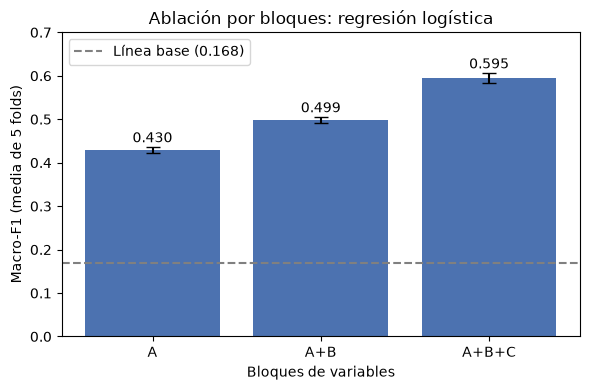

In [ ]:
#Grafica
f1 = resumen[resumen["metrica"] == "f1_macro"]
base = f1.loc[f1["modelo"] == "dummy", "media"].iloc[0]
log = f1[f1["modelo"] == "logistica"]

fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = ["A", "A+B", "A+B+C"]
ax.bar(etiquetas, log["media"], yerr=log["desv"], capsize=5, color="#4C72B0")
ax.axhline(base, color="gray", linestyle="--", label=f"Línea base ({base:.3f})")

for i, (m, d) in enumerate(zip(log["media"], log["desv"])):
    ax.text(i, m + d + 0.01, f"{m:.3f}", ha="center")

ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables")
ax.set_title("Ablación por bloques: regresión logística")
ax.set_ylim(0, 0.7)
ax.legend()

figuras = ROOT / "reports" / "figures"
figuras.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)

Connected to Python 3.14.2

In [ ]:
import pandas as pd
from ses.evaluation.metrics import SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt

from ses.config import ROOT
from ses.pipeline import cargar_entrenamiento, construir_pipeline
X, y, cv = cargar_entrenamiento()

print(X.shape, y.value_counts())

# 2. Métricas
# PROVISIONAL (Gaby): solo macro-F1, que está en la lista de metrics.py.
# Cuando Gaby suba metrics.py, este diccionario se reemplaza por un import de ahí
# (QWK, MAE ordinal, % errores a distancia >= 2, recall de Pobre).
# ---------------------------------------------------------------------------
METRICAS = {
    "f1_macro": "f1_macro",
}

#Modelo provisional mientras silva sube el pom 
MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    # PROVISIONAL (Silva): descomentar cuando suba ordinal.py
    # "ordinal_pom": lambda: ModeloOrdinal(),
}

BLOQUES = ["A", "B", "C"]
filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas de la tabla."""
    for metrica in METRICAS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque,
                          "fold": fold, "metrica": metrica, "valor": valor})



r = cross_validate(DummyClassifier(), X, y, cv=cv, scoring=METRICAS)
guardar("dummy", "ninguno", r)
print(f"{'dummy':12s} línea base: f1_macro = {r['test_f1_macro'].mean():.3f}")
# Teniendo en cuenta el resultado que fue 0.16 se espera que cualquier bloque que de verdad aprenda algo tiene que superar 0,16.

#Ablación 
for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=METRICAS)
        guardar(nombre, bloque, r)
        print(f"{nombre:12s} bloque {bloque}: f1_macro = {r['test_f1_macro'].mean():.3f}")


salida = ROOT / "reports" / "tables"
salida.mkdir(parents=True, exist_ok=True)

tabla = pd.DataFrame(filas)
tabla.to_csv(salida / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(salida / "ablacion_resumen.csv", index=False)
print(resumen)




#Grafica
f1 = resumen[resumen["metrica"] == "f1_macro"]
base = f1.loc[f1["modelo"] == "dummy", "media"].iloc[0]
log = f1[f1["modelo"] == "logistica"]

fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = ["A", "A+B", "A+B+C"]
ax.bar(etiquetas, log["media"], yerr=log["desv"], capsize=5, color="#4C72B0")
ax.axhline(base, color="gray", linestyle="--", label=f"Línea base ({base:.3f})")

for i, (m, d) in enumerate(zip(log["media"], log["desv"])):
    ax.text(i, m + d + 0.01, f"{m:.3f}", ha="center")

ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables")
ax.set_title("Ablación por bloques: regresión logística")
ax.set_ylim(0, 0.7)
ax.legend()

figuras = ROOT / "reports" / "figures"
figuras.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)

(15728, 32) ses
2    7929
1    3701
0    3402
3     696
Name: count, dtype: int64


NameError: name 'DummyClassifier' is not defined

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate

from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline

# El POM de Silva (src/ses/models/ordinal.py). Si todavía no está en la rama o su
# archivo tiene un error, la ablación corre solo con la logística y AVISA el motivo.
try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error

# ---------------------------------------------------------------------------
# 1. Datos: solo el 80 % de entrenamiento y sus 5 folds. La prueba no se toca.
# ---------------------------------------------------------------------------
X, y, cv = cargar_entrenamiento()

# ---------------------------------------------------------------------------
# 2. Modelos. Cada valor crea un modelo NUEVO, para que ningún bloque reutilice
#    un modelo ya entrenado. Los dos usan class_weight="balanced" (decisión 27).
# ---------------------------------------------------------------------------
MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda: POM(class_weight="balanced")
else:
    print(f"AVISO: no se pudo usar el POM ({ERROR_POM}); corre solo la logística.")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}

# ---------------------------------------------------------------------------
# 3. Validación cruzada: línea base + cada modelo con cada bloque
# ---------------------------------------------------------------------------
filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

# ---------------------------------------------------------------------------
# 4. Guardar tablas
# ---------------------------------------------------------------------------
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())

# ---------------------------------------------------------------------------
# 5. Gráficas para el informe
#    Un color por modelo (el mismo en todas las figuras) y la línea base en gris
#    punteado. Los ejes empiezan en 0 para no exagerar las diferencias.
# ---------------------------------------------------------------------------
COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


# 5.1 Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

# 5.2 Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# 5.3 Matrices de confusión del modelo principal: ¿dónde se equivoca?
#     cross_val_predict da, para cada hogar, la predicción del fold en que fue validación.
#     Se normaliza por fila: % de cada clase real que cae en cada clase predicha.
nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

AVISO: no se pudo usar el POM (cannot import name 'POM' from 'ses.models.ordinal' (C:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\models\ordinal.py)); corre solo la logística.


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


baseline   línea base: f1_macro = 0.168
logistica  bloque A     : f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B   : f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B+C : f1_macro = 0.595
metrica                       f1_macro    qwk  mae_ordinal  pct_errores_lejanos  recall_pobre  recall_alta
modelo               bloque                                                                               
baseline_mayoritaria ninguno     0.168  0.000        0.712                0.216         0.000        0.000
logistica            A           0.430  0.521        0.642                0.102         0.535        0.790
                     B           0.499  0.611        0.532                0.067         0.590        0.823
                     C           0.595  0.733        0.392                0.030         0.723        0.849


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. 

Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate

from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline

.
try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error


X, y, cv = cargar_entrenamiento()


MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda: POM(class_weight="balanced")
else:
    print(f"AVISO: no se pudo usar el POM ({ERROR_POM}); corre solo la logística.")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}


filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())


# Gráficas para el informe

COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


#  Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

# Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# 5.3 Matrices de confusión del modelo principal: ¿dónde se equivoca?

nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

SyntaxError: invalid syntax (<ipython-input-3-63e3bb34b00b>, line 14)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate

from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline


try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error


X, y, cv = cargar_entrenamiento()


MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda: POM(class_weight="balanced")
else:
    print(f"AVISO: no se pudo usar el POM ({ERROR_POM}); corre solo la logística.")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}


filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())


# Gráficas para el informe

COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


#  Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

# Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# 5.3 Matrices de confusión del modelo principal: ¿dónde se equivoca?

nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

AVISO: no se pudo usar el POM (cannot import name 'POM' from 'ses.models.ordinal' (C:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\models\ordinal.py)); corre solo la logística.


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


baseline   línea base: f1_macro = 0.168
logistica  bloque A     : f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B   : f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B+C : f1_macro = 0.595
metrica                       f1_macro    qwk  mae_ordinal  pct_errores_lejanos  recall_pobre  recall_alta
modelo               bloque                                                                               
baseline_mayoritaria ninguno     0.168  0.000        0.712                0.216         0.000        0.000
logistica            A           0.430  0.521        0.642                0.102         0.535        0.790
                     B           0.499  0.611        0.532                0.067         0.590        0.823
                     C           0.595  0.733        0.392                0.030         0.723        0.849


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. 

Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate

from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline


try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error


X, y, cv = cargar_entrenamiento()


MODELOS = {
    "logistica": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda: POM(class_weight="balanced")
else:
    print(f"AVISO: no se pudo usar el POM ({ERROR_POM}); corre solo la logística.")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}


filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())


# Gráficas para el informe

COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


#  Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

# Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# 5.3 Matrices de confusión del modelo principal: ¿dónde se equivoca?

nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

AVISO: no se pudo usar el POM (cannot import name 'POM' from 'ses.models.ordinal' (C:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\models\ordinal.py)); corre solo la logística.


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


baseline   línea base: f1_macro = 0.168
logistica  bloque A     : f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B   : f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B+C : f1_macro = 0.595
metrica                       f1_macro    qwk  mae_ordinal  pct_errores_lejanos  recall_pobre  recall_alta
modelo               bloque                                                                               
baseline_mayoritaria ninguno     0.168  0.000        0.712                0.216         0.000        0.000
logistica            A           0.430  0.521        0.642                0.102         0.535        0.790
                     B           0.499  0.611        0.532                0.067         0.590        0.823
                     C           0.595  0.733        0.392                0.030         0.723        0.849


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. 

Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate

from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline

# El POM de Silva (src/ses/models/ordinal.py). Si todavía no está en la rama o su
# archivo tiene un error, la ablación corre solo con la logística y AVISA el motivo.
try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error


X, y, cv = cargar_entrenamiento()


# C de la logística por bloque: sale de ajuste_hiperparametros.py (decisión 34).
# Si todavía no se ha corrido el ajuste, usa C = 1 (el valor por defecto) y avisa.
archivo_C = ROOT / "reports" / "tables" / "mejores_C.csv"
if archivo_C.exists():
    C_POR_BLOQUE = pd.read_csv(archivo_C).set_index("bloque")["mejor_C"].to_dict()
else:
    C_POR_BLOQUE = {}
    print("AVISO: no existe mejores_C.csv; la logística usa C = 1. Corre antes ajuste_hiperparametros.py")

# Los dos modelos usan class_weight="balanced" (decisiones 31 y 33).
MODELOS = {
    "logistica": lambda bloque: LogisticRegression(C=C_POR_BLOQUE.get(bloque, 1.0),
                                                   max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda bloque: POM(class_weight="balanced")
else:
    print(f"AVISO: no se pudo usar el POM ({ERROR_POM}); corre solo la logística.")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}


filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(bloque), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())


# Gráficas para el informe

COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


# 5.1 Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

# 5.2 Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# 5.3 Matrices de confusión del modelo principal: ¿dónde se equivoca?
#     cross_val_predict da, para cada hogar, la predicción del fold en que fue validación.
#     Se normaliza por fila: % de cada clase real que cae en cada clase predicha.
nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](bloque), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

AVISO: no existe mejores_C.csv; la logística usa C = 1. Corre antes ajuste_hiperparametros.py
AVISO: no se pudo usar el POM (cannot import name 'POM' from 'ses.models.ordinal' (C:\Users\juana\OneDrive\Documents\GitHub\ML-Household-Socioeconomic-Status\src\ses\models\ordinal.py)); corre solo la logística.


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


baseline   línea base: f1_macro = 0.168
logistica  bloque A     : f1_macro = 0.430


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B   : f1_macro = 0.499


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


logistica  bloque A+B+C : f1_macro = 0.595
metrica                       f1_macro    qwk  mae_ordinal  pct_errores_lejanos  recall_pobre  recall_alta
modelo               bloque                                                                               
baseline_mayoritaria ninguno     0.168  0.000        0.712                0.216         0.000        0.000
logistica            A           0.430  0.521        0.642                0.102         0.535        0.790
                     B           0.499  0.611        0.532                0.067         0.590        0.823
                     C           0.595  0.733        0.392                0.030         0.723        0.849


c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\juana\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. 

Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
 
from ses.config import ROOT
from ses.pipeline import cargar_entrenamiento, construir_pipeline
 

X, y, cv = cargar_entrenamiento()
 


#    C es el INVERSO de la fuerza de regularización: C pequeño = modelo más simple.
#    Solo penalización L2 (la de por defecto); L1 queda en los candidatos de Gaby.

GRILLA_C = [0.001, 0.01, 0.1, 1, 10, 100]
param_grid = {"modelo__C": GRILLA_C}      # "modelo" es el nombre del paso en construir_pipeline
 
BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}
 
mejores = []   # mejor C de cada bloque → mejores_C.csv
detalle = []   # todos los C probados   → ajuste_C_detalle.csv

#  Búsqueda por bloque 
for bloque in BLOQUES:
    modelo = LogisticRegression(max_iter=3000, class_weight="balanced")   # decisión 33
    pipe = construir_pipeline(modelo, bloque)
 
    busqueda = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    busqueda.fit(X, y)
 
    res = busqueda.cv_results_
    i = busqueda.best_index_
    mejor_C = busqueda.best_params_["modelo__C"]
    mejores.append({"bloque": bloque, "mejor_C": mejor_C,
                    "f1_macro_media": res["mean_test_score"][i],
                    "f1_macro_desv": res["std_test_score"][i],
                    "en_borde_grilla": mejor_C in (GRILLA_C[0], GRILLA_C[-1])})
 
    for C, media, desv in zip(GRILLA_C, res["mean_test_score"], res["std_test_score"]):
        detalle.append({"bloque": bloque, "C": C, "f1_macro_media": media, "f1_macro_desv": desv})
 
    aviso = "  ← en el borde de la grilla: revisar" if mejor_C in (GRILLA_C[0], GRILLA_C[-1]) else ""
    print(f"Bloque {ETIQUETA_BLOQUE[bloque]:6s}: mejor C = {mejor_C:<6}  "
          f"f1_macro = {res['mean_test_score'][i]:.3f} ± {res['std_test_score'][i]:.3f}{aviso}")
#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)
 
pd.DataFrame(mejores).round(4).to_csv(tablas / "mejores_C.csv", index=False)
detalle = pd.DataFrame(detalle).round(4)
detalle.to_csv(tablas / "ajuste_C_detalle.csv", index=False)
 

# Figura: macro-F1 según C (escala logarítmica), una línea por bloque

COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 4.2))
for bloque in BLOQUES:
    d = detalle[detalle["bloque"] == bloque]
    ax.errorbar(d["C"], d["f1_macro_media"], yerr=d["f1_macro_desv"], marker="o",
                capsize=3, linewidth=2, color=COLOR[bloque], label=ETIQUETA_BLOQUE[bloque])
ax.set_xscale("log")
ax.set_ylim(0, 0.75)
ax.set_xlabel("C (escala logarítmica; mayor C = menos regularización)")
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_title("Ajuste de C de la regresión logística por bloque")
ax.legend(title="Bloques", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figuras / "ajuste_C.png", dpi=150)
plt.close(fig)
 
print("Guardado: mejores_C.csv, ajuste_C_detalle.csv y ajuste_C.png")

Bloque A     : mejor C = 100     f1_macro = 0.431 ± 0.006  ← en el borde de la grilla: revisar
Bloque A+B   : mejor C = 0.1     f1_macro = 0.499 ± 0.009
Bloque A+B+C : mejor C = 1       f1_macro = 0.595 ± 0.011
Guardado: mejores_C.csv, ajuste_C_detalle.csv y ajuste_C.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
 
from ses.config import ROOT
from ses.pipeline import cargar_entrenamiento, construir_pipeline
 

X, y, cv = cargar_entrenamiento()
 


#    C es el INVERSO de la fuerza de regularización: C pequeño = modelo más simple.
#    Solo penalización L2 (la de por defecto); L1 queda en los candidatos de Gaby.

GRILLA_C = [0.001, 0.01, 0.1, 1, 10, 100]
param_grid = {"modelo__C": GRILLA_C}      # "modelo" es el nombre del paso en construir_pipeline
 
BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}
 
mejores = []   # mejor C de cada bloque → mejores_C.csv
detalle = []   # todos los C probados   → ajuste_C_detalle.csv

#  Búsqueda por bloque 
for bloque in BLOQUES:
    modelo = LogisticRegression(max_iter=3000, class_weight="balanced")   # decisión 33
    pipe = construir_pipeline(modelo, bloque)
 
    busqueda = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    busqueda.fit(X, y)
 
    res = busqueda.cv_results_
    i = busqueda.best_index_
    mejor_C = busqueda.best_params_["modelo__C"]
    mejores.append({"bloque": bloque, "mejor_C": mejor_C,
                    "f1_macro_media": res["mean_test_score"][i],
                    "f1_macro_desv": res["std_test_score"][i],
                    "en_borde_grilla": mejor_C in (GRILLA_C[0], GRILLA_C[-1])})
 
    for C, media, desv in zip(GRILLA_C, res["mean_test_score"], res["std_test_score"]):
        detalle.append({"bloque": bloque, "C": C, "f1_macro_media": media, "f1_macro_desv": desv})
 
    aviso = "  ← en el borde de la grilla: revisar" if mejor_C in (GRILLA_C[0], GRILLA_C[-1]) else ""
    print(f"Bloque {ETIQUETA_BLOQUE[bloque]:6s}: mejor C = {mejor_C:<6}  "
          f"f1_macro = {res['mean_test_score'][i]:.3f} ± {res['std_test_score'][i]:.3f}{aviso}")
#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)
 
pd.DataFrame(mejores).round(4).to_csv(tablas / "mejores_C.csv", index=False)
detalle = pd.DataFrame(detalle).round(4)
detalle.to_csv(tablas / "ajuste_C_detalle.csv", index=False)
 

# Figura: macro-F1 según C (escala logarítmica), una línea por bloque

COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 4.2))
for bloque in BLOQUES:
    d = detalle[detalle["bloque"] == bloque]
    ax.errorbar(d["C"], d["f1_macro_media"], yerr=d["f1_macro_desv"], marker="o",
                capsize=3, linewidth=2, color=COLOR[bloque], label=ETIQUETA_BLOQUE[bloque])
ax.set_xscale("log")
ax.set_ylim(0, 0.75)
ax.set_xlabel("C (escala logarítmica; mayor C = menos regularización)")
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_title("Ajuste de C de la regresión logística por bloque")
ax.legend(title="Bloques", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figuras / "ajuste_C.png", dpi=150)
plt.close(fig)
 
print("Guardado: mejores_C.csv, ajuste_C_detalle.csv y ajuste_C.png")

Bloque A     : mejor C = 100     f1_macro = 0.431 ± 0.006  ← en el borde de la grilla: revisar
Bloque A+B   : mejor C = 0.1     f1_macro = 0.499 ± 0.009
Bloque A+B+C : mejor C = 1       f1_macro = 0.595 ± 0.011
Guardado: mejores_C.csv, ajuste_C_detalle.csv y ajuste_C.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, cross_validate
import warnings

# Categorías raras no vistas en un fold → se codifican como ceros (decisión 32).
warnings.filterwarnings("ignore", message="Found unknown categories")
from ses.config import ROOT
from ses.evaluation.metrics import CLASES, MENOR_ES_MEJOR, NOMBRES_CLASES, SCORERS, a_signo_normal
from ses.models.baseline import evaluar_baseline
from ses.pipeline import cargar_entrenamiento, construir_pipeline

# El POM de Silva (src/ses/models/ordinal.py). Si todavía no está en la rama o su
# archivo tiene un error, la ablación corre solo con la logística y AVISA el motivo.
try:
    from ses.models.ordinal import POM
    ERROR_POM = None
except (ImportError, SyntaxError) as error:
    POM, ERROR_POM = None, error


X, y, cv = cargar_entrenamiento()


# C de la logística por bloque: sale de ajuste_hiperparametros.py (decisión 34).
# Si todavía no se ha corrido el ajuste, usa C = 1 (el valor por defecto) y avisa.
archivo_C = ROOT / "reports" / "tables" / "mejores_C.csv"
if archivo_C.exists():
    C_POR_BLOQUE = pd.read_csv(archivo_C).set_index("bloque")["mejor_C"].to_dict()
else:
    C_POR_BLOQUE = {}
    print("AVISO: no existe mejores_C.csv; la logística usa C = 1. Corre antes ajuste_hiperparametros.py")


# C de la logística por bloque: sale de ajuste_hiperparametros.py (decisión 34).
# Si todavía no se ha corrido el ajuste, usa C = 1 (el valor por defecto) y avisa.
archivo_C = ROOT / "reports" / "tables" / "mejores_C.csv"
if archivo_C.exists():
    C_POR_BLOQUE = pd.read_csv(archivo_C).set_index("bloque")["mejor_C"].to_dict()
else:
    C_POR_BLOQUE = {}
    print("AVISO: no existe mejores_C.csv; la logística usa C = 1. Corre antes ajuste_hiperparametros.py")

# Los dos modelos usan class_weight="balanced" (decisiones 31 y 33).
MODELOS = {
    "logistica": lambda bloque: LogisticRegression(C=C_POR_BLOQUE.get(bloque, 1.0),
                                                   max_iter=3000, class_weight="balanced"),
}
if POM is not None:
    MODELOS["pom"] = lambda bloque: POM(class_weight="balanced")

# Modelo principal del proyecto (el del paper): el POM si está; si no, la logística
PRINCIPAL = "pom" if "pom" in MODELOS else "logistica"

BLOQUES = ["A", "B", "C"]
ETIQUETA_BLOQUE = {"A": "A", "B": "A+B", "C": "A+B+C"}       # los bloques son acumulativos
NOMBRE_MODELO = {"logistica": "Logística multinomial", "pom": "Logística ordinal (POM)"}


filas = []  # una fila por cada número, formato del contrato


def guardar(modelo, bloque, resultado):
    """Pasa los 5 puntajes de cada métrica a filas, con su signo normal."""
    for metrica in SCORERS:
        for fold, valor in enumerate(resultado[f"test_{metrica}"], start=1):
            filas.append({"modelo": modelo, "bloque": bloque, "fold": fold,
                          "metrica": metrica, "valor": a_signo_normal(metrica, valor)})


# Línea base del equipo (Gaby): clase mayoritaria, mismos folds y mismas métricas
base_df = evaluar_baseline(X, y, cv)
f1_base = base_df.loc[base_df["metrica"] == "f1_macro", "valor"].mean()
print(f"{'baseline':10s} línea base: f1_macro = {f1_base:.3f}")

for nombre, crear_modelo in MODELOS.items():
    for bloque in BLOQUES:
        pipe = construir_pipeline(crear_modelo(bloque), bloque)
        r = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS)
        guardar(nombre, bloque, r)
        print(f"{nombre:10s} bloque {ETIQUETA_BLOQUE[bloque]:6s}: "
              f"f1_macro = {r['test_f1_macro'].mean():.3f}")

#Tablas 
tablas = ROOT / "reports" / "tables"
figuras = ROOT / "reports" / "figures"
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

tabla = pd.concat([base_df, pd.DataFrame(filas)], ignore_index=True)
tabla.to_csv(tablas / "ablacion.csv", index=False)

resumen = (tabla.groupby(["modelo", "bloque", "metrica"])["valor"]
                .agg(media="mean", desv="std")
                .round(3)
                .reset_index())
resumen.to_csv(tablas / "ablacion_resumen.csv", index=False)

# Vista ancha para leer en la terminal: una fila por modelo y bloque, una columna por métrica
print(resumen.pivot_table(index=["modelo", "bloque"], columns="metrica", values="media")
             [list(SCORERS)].to_string())


# Gráficas para el informe

COLOR = {"logistica": "#2a78d6", "pom": "#eb6834"}
GRIS = "#52514e"
modelos = list(MODELOS)
x = np.arange(len(BLOQUES))
ancho = 0.8 / len(modelos)


def barras(ax, metrica, etiquetas_valor=False):
    """Barras por bloque (una por modelo), con desviación estándar y línea base."""
    for i, m in enumerate(modelos):
        d = (resumen[(resumen["modelo"] == m) & (resumen["metrica"] == metrica)]
             .set_index("bloque").loc[BLOQUES])
        pos = x + (i - (len(modelos) - 1) / 2) * ancho
        ax.bar(pos, d["media"], ancho * 0.92, yerr=d["desv"], capsize=3,
               color=COLOR[m], label=NOMBRE_MODELO[m])
        if etiquetas_valor:
            for p, v, s in zip(pos, d["media"], d["desv"]):
                ax.text(p, v + s + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    base = resumen.loc[(resumen["modelo"] == "baseline_mayoritaria")
                       & (resumen["metrica"] == metrica), "media"]
    if len(base):
        ax.axhline(base.iloc[0], color=GRIS, linestyle="--", linewidth=1,
                   label=f"Línea base ({base.iloc[0]:.3f})")
    ax.set_xticks(x, [ETIQUETA_BLOQUE[b] for b in BLOQUES])
    ax.spines[["top", "right"]].set_visible(False)


#  Figura principal: macro-F1 por bloque
fig, ax = plt.subplots(figsize=(7, 4.2))
barras(ax, "f1_macro", etiquetas_valor=True)
ax.set_ylim(0, 0.75)
ax.set_ylabel("Macro-F1 (media de 5 folds)")
ax.set_xlabel("Bloques de variables (acumulativos)")
ax.set_title("Ablación por bloques: macro-F1")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figuras / "ablacion.png", dpi=150)
plt.close(fig)

#  Las 6 métricas del equipo, un panel por métrica (cada una con su propia escala)
TITULO = {
    "f1_macro": "Macro-F1", "qwk": "QWK", "mae_ordinal": "MAE ordinal (clases)",
    "pct_errores_lejanos": "Errores a distancia ≥ 2", "recall_pobre": "Recall de Pobre",
    "recall_alta": "Recall de Alta",
}
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metrica in zip(ejes.flat, SCORERS):
    barras(ax, metrica)
    sentido = "↓ menor es mejor" if metrica in MENOR_ES_MEJOR else "↑ mayor es mejor"
    ax.set_title(f"{TITULO.get(metrica, metrica)}\n({sentido})", fontsize=10)
    ax.set_ylim(bottom=0)
manejadores, nombres = ejes.flat[0].get_legend_handles_labels()
fig.legend(manejadores, nombres, loc="lower center", ncol=len(nombres), frameon=False, fontsize=9)
fig.suptitle("Ablación por bloques: métricas del equipo (media ± desv. en 5 folds)")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(figuras / "ablacion_metricas.png", dpi=150)
plt.close(fig)

# Matrices de confusión del modelo principal: ¿dónde se equivoca?
#     cross_val_predict da, para cada hogar, la predicción del fold en que fue validación.
#     Se normaliza por fila: % de cada clase real que cae en cada clase predicha.
nombres_clases = [NOMBRES_CLASES[c] for c in CLASES]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, bloque in zip(ejes, ["B", "C"]):
    pred = cross_val_predict(construir_pipeline(MODELOS[PRINCIPAL](bloque), bloque), X, y, cv=cv)
    cm = confusion_matrix(y, pred, labels=CLASES, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > 55 else "black")
    ax.set_xticks(range(len(CLASES)), nombres_clases)
    ax.set_yticks(range(len(CLASES)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{NOMBRE_MODELO[PRINCIPAL]}: bloques {ETIQUETA_BLOQUE[bloque]}", fontsize=10)
fig.suptitle("¿Dónde se equivoca el modelo? (% de cada clase real, 5 folds)")
fig.tight_layout()
fig.savefig(figuras / "ablacion_confusion.png", dpi=150)
plt.close(fig)

print("Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/")

baseline   línea base: f1_macro = 0.168
logistica  bloque A     : f1_macro = 0.431
logistica  bloque A+B   : f1_macro = 0.499
logistica  bloque A+B+C : f1_macro = 0.595
metrica                       f1_macro    qwk  mae_ordinal  pct_errores_lejanos  recall_pobre  recall_alta
modelo               bloque                                                                               
baseline_mayoritaria ninguno     0.168  0.000        0.712                0.216         0.000        0.000
logistica            A           0.431  0.521        0.641                0.102         0.535        0.790
                     B           0.499  0.609        0.534                0.069         0.595        0.828
                     C           0.595  0.733        0.392                0.030         0.723        0.849
Guardado: ablacion.csv, ablacion_resumen.csv y 3 figuras en reports/


No kernel connected